In [1]:
import os

# os.environ["HF_HOME"] = "/mnt/disks/ai-training/hf_cache"

import copy
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
import timm

from einops import rearrange
from skimage import data as skdata
from timm.utils.model import reparameterize_model

from vision_transformer import VisionTransformer, Attention, Block
from lecture_utils import (
    get_device, set_seed, count_params, benchmark_fn, denormalize, download_fastai_subset, make_eval_loader,
    evaluate_on_imagenet_subset, count_gmacs, measure_throughput,
)

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)

In [2]:
DEVICE = get_device()
NUM_WORKERS = 4
DATA_DIR = "../../data"
RESULTS_DIR = "results"
# The benchmarks (16 checkpoints, ToMe sweep, FLOP scaling) take ~10 min on an RTX 5090 and much longer on a laptop.
# Set to False to load the precomputed tables from `results/` instead.
RUN_EXPERIMENTS = True
os.makedirs(RESULTS_DIR, exist_ok=True)

set_seed(95431)
print(f"torch {torch.__version__} | timm {timm.__version__} | device: {DEVICE}")

torch 2.8.0+cu128 | timm 1.0.30 | device: cuda


# Agenda

1. [The ViT family tree](#Family_Tree)
2. [Data and evaluation protocol](#Data)
3. [Data-efficient ViTs: DeiT and friends](#DeiT)
4. [Positional information, flexible resolution and extra tokens](#Positions)
5. [Hierarchical transformers: PVT and Swin](#Hierarchical)
6. [Efficient attention](#Efficient_Attention)
7. [Hybrid convolutional-transformer architectures](#Hybrid)
8. [Plain ViTs for dense prediction](#Dense)
9. [Where the field is in 2025–2026](#SOTA_2026)
10. [Benchmark: 16 architectures on the same data](#Benchmark)
11. [How to choose a backbone](#Choose)
12. [Summary and self-check questions](#Summary)
13. [Appendix](#Appendix): A. linear attention, B. [CLS] vs [DIST] tokens in DeiT

# Resources

**Data-efficient training and tokens**
- [DeiT: Training data-efficient image transformers & distillation through attention (Touvron et al., 2020)](https://arxiv.org/abs/2012.12877)
- [CaiT: Going deeper with Image Transformers (LayerScale, class-attention; Touvron et al., 2021)](https://arxiv.org/abs/2103.17239)
- [DeiT III: Revenge of the ViT (Touvron et al., 2022)](https://arxiv.org/abs/2204.07118)
- [CPVT: Conditional Positional Encodings for Vision Transformers (Chu et al., 2021)](https://arxiv.org/abs/2102.10882)
- [RoFormer: Rotary Position Embedding (Su et al., 2021)](https://arxiv.org/abs/2104.09864) and [Rotary Position Embedding for Vision Transformer (Heo et al., 2024)](https://arxiv.org/abs/2403.13298)
- [Vision Transformers Need Registers (Darcet et al., 2023)](https://arxiv.org/abs/2309.16588)
- [Scaling Vision Transformers to 22 Billion Parameters (QK-norm, Dehghani et al., 2023)](https://arxiv.org/abs/2302.05442) and [Small-scale proxies for large-scale Transformer training instabilities (Wortsman et al., 2023)](https://arxiv.org/abs/2309.14322)
- [FlexiViT: One Model for All Patch Sizes (Beyer et al., 2023)](https://arxiv.org/abs/2212.08013) and [NaViT: Patch n' Pack (Dehghani et al., 2023)](https://arxiv.org/abs/2307.06304)

**Hierarchical and efficient attention**
- [PVT: Pyramid Vision Transformer (Wang et al., 2021)](https://arxiv.org/abs/2102.12122) and [PVTv2 (2021)](https://arxiv.org/abs/2106.13797)
- [Swin Transformer: Hierarchical Vision Transformer using Shifted Windows (Liu et al., 2021)](https://arxiv.org/abs/2103.14030) and [Swin V2 (2021)](https://arxiv.org/abs/2111.09883)
- [Hiera: A Hierarchical Vision Transformer without the Bells-and-Whistles (Ryali et al., 2023)](https://arxiv.org/abs/2306.00989)
- [Transformers are RNNs: Linear Attention (Katharopoulos et al., 2020)](https://arxiv.org/abs/2006.16236), [Linformer](https://arxiv.org/abs/2006.04768), [Performer](https://arxiv.org/abs/2009.14794)
- [FlashAttention (Dao et al., 2022)](https://arxiv.org/abs/2205.14135)
- [ToMe: Token Merging: Your ViT But Faster (Bolya et al., 2022)](https://arxiv.org/abs/2210.09461)

**Hybrids and CNN answer**
- [Early Convolutions Help Transformers See Better (Xiao et al., 2021)](https://arxiv.org/abs/2106.14881)
- [CvT (Wu et al., 2021)](https://arxiv.org/abs/2103.15808), [CoAtNet (Dai et al., 2021)](https://arxiv.org/abs/2106.04803), [LeViT (Graham et al., 2021)](https://arxiv.org/abs/2104.01136)
- [MobileViT (Mehta & Rastegari, 2021)](https://arxiv.org/abs/2110.02178), [EfficientFormer (Li et al., 2022)](https://arxiv.org/abs/2206.01191), [FastViT (Vasu et al., 2023)](https://arxiv.org/abs/2303.14189)
- [MaxViT: Multi-Axis Vision Transformer (Tu et al., 2022)](https://arxiv.org/abs/2204.01697)
- [ConvNeXt: A ConvNet for the 2020s (Liu et al., 2022)](https://arxiv.org/abs/2201.03545)

**Vision encoders 2025–2026**
- [DINOv3 (Siméoni et al., 2025)](https://arxiv.org/abs/2508.10104)
- [SigLIP 2 (Tschannen et al., 2025)](https://arxiv.org/abs/2502.14786)
- [Perception Encoder (Bolya et al., 2025)](https://arxiv.org/abs/2504.13181)
- [SAM 3: Segment Anything with Concepts (2025)](https://arxiv.org/abs/2511.16719)
- [C-RADIOv4 tech report (NVIDIA, 2026)](https://arxiv.org/abs/2601.17237)

**Dense prediction**
- [ViTDet: Exploring Plain Vision Transformer Backbones for Object Detection (Li et al., 2022)](https://arxiv.org/abs/2203.16527)
- [ViT-Adapter (Chen et al., 2022)](https://arxiv.org/abs/2205.08534), [Segment Anything (Kirillov et al., 2023)](https://arxiv.org/abs/2304.02643)

**Code**
- [timm model zoo](https://github.com/huggingface/pytorch-image-models) and [timm ImageNet results tables](https://github.com/huggingface/pytorch-image-models/tree/main/results)
- [microsoft/Swin-Transformer](https://github.com/microsoft/Swin-Transformer), [facebookresearch/deit](https://github.com/facebookresearch/deit), [facebookresearch/ToMe](https://github.com/facebookresearch/ToMe)

<a id='Family_Tree'></a>
# The ViT family tree

In Lecture 1 we built the "vanilla" ViT from scratch (the code is in `vision_transformer.py`) and saw its three weak spots:

1. **Data hunger.** Weak inductive bias $\Rightarrow$ poor results when trained from scratch on ImageNet-1k-sized (or smaller) data.
2. **Quadratic cost and a single scale.** $\mathcal{O}(N^2)$ attention prevents high resolution; a single $1/16$-resolution feature map does not fit detection/segmentation heads that expect a pyramid of features ($1/4 \dots 1/32$) like a ResNet provides.
3. **Optimization and "hygiene".** Training instabilities at depth/scale, artifacts in attention maps, position encodings that do not transfer across resolutions.

Almost every architecture after 2020 can be understood as an answer to one (or several) of these problems:

| Direction | Problem addressed | Key idea | Representatives |
|---|---|---|---|
| **Better training of plain ViT** | data hunger | recipe, augmentation, distillation | DeiT, DeiT III, AugReg, CaiT |
| **Stability / "hygiene"** | instabilities at scale, artifacts | LayerScale, QK-norm, register tokens | CaiT, ViT-22B, DINOv2+reg |
| **Better positions / flexible resolution** | resolution transfer | relative/conditional/rotary positions, patch-size and aspect-ratio flexibility | Swin RPB, CPVT, RoPE-ViT, FlexiViT, NaViT |
| **Hierarchical (pyramid) transformers** | single scale, cost | downsample tokens between stages | PVT, Swin, MViT, Hiera |
| **Efficient attention** | $\mathcal{O}(N^2)$ | local windows, reduced K/V, linear kernels, IO-aware kernels, fewer tokens | Swin, PVT, MaxViT, Performer, FlashAttention, ToMe |
| **Hybrids (conv + attention)** | inductive bias, latency | convolutions in early stages / inside blocks | CvT, CoAtNet, LeViT, MobileViT, EfficientFormer, FastViT, MaxViT |
| **Modernized CNNs** | "is attention even needed?" | take ViT design choices into a CNN | ConvNeXt |
| **Plain ViT at scale** | "just scale it" | keep plain ViT, adapt at the head | ViTDet, SAM / SAM 3, EVA, DINOv2 / DINOv3, C-RADIO |

We will walk through these directions, implement the key mechanism of each from scratch, and at the end benchmark 16 pretrained models side by side.

<a id='Data'></a>
# Data and evaluation protocol

To compare architectures **without training anything** we take ImageNet-1k checkpoints from `timm` and evaluate them on [Imagewoof](https://github.com/fastai/imagenette) — a fast.ai subset of ImageNet with **10 dog breeds** (hard, fine-grained classes). Its folders are ImageNet WordNet ids, so we restrict each model's 1000 logits to these 10 classes and compute top-1 accuracy.

> ⚠️ Imagewoof images come from ImageNet, so they may overlap with the models' training data. Treat the numbers as a *consistent relative comparison*, not as a generalization estimate. For proper numbers see the [timm results tables](https://github.com/huggingface/pytorch-image-models/tree/main/results).

In [3]:
IMAGEWOOF_ROOT = download_fastai_subset(DATA_DIR, "imagewoof2-320")
IMAGEWOOF_VAL = os.path.join(IMAGEWOOF_ROOT, "val")

from torchvision.datasets import ImageFolder
from timm.data import ImageNetInfo

woof_val = ImageFolder(IMAGEWOOF_VAL)
imagenet_info = ImageNetInfo()
print(f"Imagewoof val: {len(woof_val)} images")
for wnid in woof_val.classes:
    print(f"  {wnid} -> {imagenet_info.label_name_to_description(wnid)}")

Imagewoof val: 3929 images
  n02086240 -> Shih-Tzu
  n02087394 -> Rhodesian ridgeback
  n02088364 -> beagle
  n02089973 -> English foxhound
  n02093754 -> Border terrier
  n02096294 -> Australian terrier
  n02099601 -> golden retriever
  n02105641 -> Old English sheepdog, bobtail
  n02111889 -> Samoyed, Samoyede
  n02115641 -> dingo, warrigal, warragal, Canis dingo


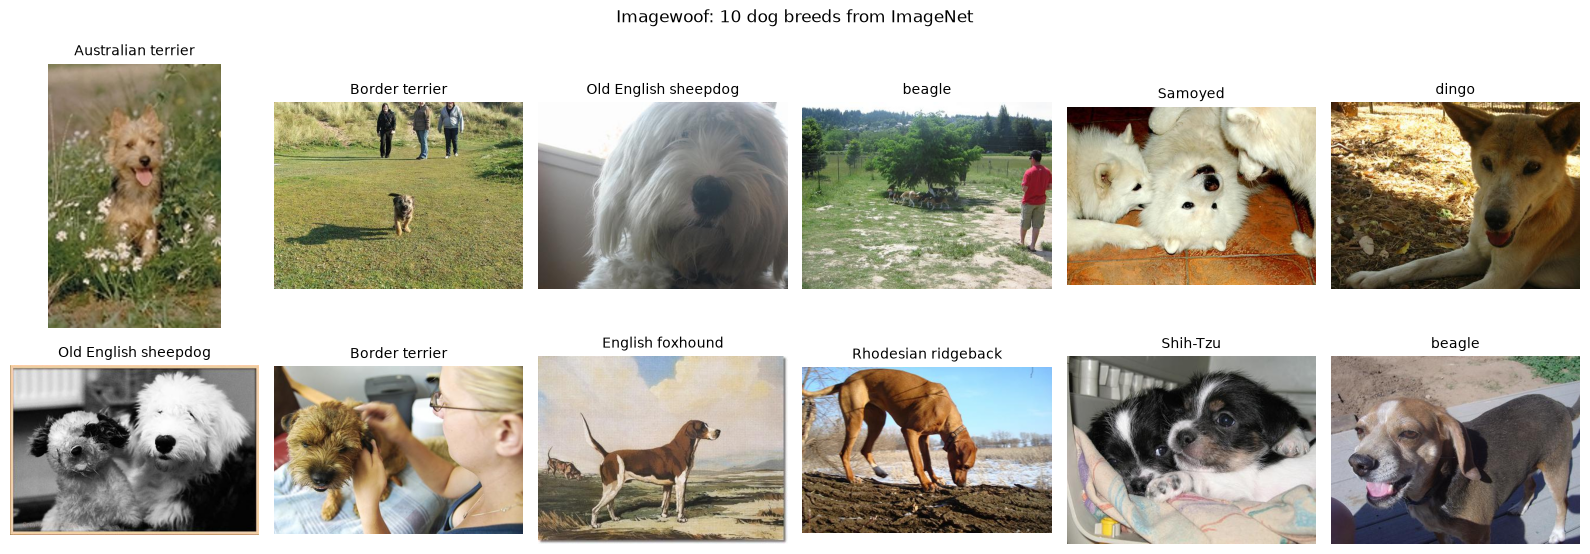

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, idx in zip(axes.flatten(), np.random.choice(len(woof_val), 12, replace=False)):
    img, label = woof_val[idx]
    ax.imshow(img)
    ax.set_title(imagenet_info.label_name_to_description(woof_val.classes[label]).split(",")[0], fontsize=10)
    ax.axis("off")
plt.suptitle("Imagewoof: 10 dog breeds from ImageNet")
plt.tight_layout()
plt.show()

In [5]:
natural_images = {"chelsea": skdata.chelsea(), "astronaut": skdata.astronaut(), "coffee": skdata.coffee(), "rocket": skdata.rocket()}


def preprocess_for(model, images, size=None):
    cfg = timm.data.resolve_data_config({}, model=model)
    size = size or cfg["input_size"][-1]
    tfm = T.Compose([T.ToPILImage(), T.Resize(size, interpolation=T.InterpolationMode.BICUBIC), T.CenterCrop(size),
                     T.ToTensor(), T.Normalize(cfg["mean"], cfg["std"])])
    return torch.stack([tfm(img) for img in images]), cfg["mean"], cfg["std"]

<a id='DeiT'></a>
# Data-efficient ViTs: DeiT and friends

<img src="https://raw.githubusercontent.com/facebookresearch/deit/main/.github/deit.png" width="500">

**DeiT** (Touvron et al., 2020) showed that a ViT-B can reach **81.8%** on ImageNet-1k **without** extra data — the ViT paper got 77.9% in the same setting. The architecture is *unchanged*; the difference is:

### 1. The training recipe
300 epochs with AdamW (lr $5 \cdot 10^{-4} \cdot \frac{\text{batch}}{512}$, wd 0.05), cosine schedule with warmup, **RandAugment**, **Mixup** + **CutMix**, **Random Erasing**, **stochastic depth** 0.1, **repeated augmentation**, label smoothing. Ablations in the paper show that removing Mixup/CutMix or RandAugment costs several points — heavy augmentation plays the role of the missing inductive bias.

### 2. Distillation through attention
A new learnable **distillation token** is appended next to [CLS]. It interacts with all patch tokens through attention, and its output goes to a separate head trained to reproduce the **teacher's** predictions (a strong CNN, RegNetY-16GF):

$$
\mathcal{L}_{\text{hard}} = \tfrac{1}{2}\, \mathcal{L}_{CE}\big(\psi(Z_{cls}), y\big) + \tfrac{1}{2}\, \mathcal{L}_{CE}\big(\psi(Z_{dist}), y_t\big), \qquad y_t = \arg\max_c Z_t(c),
$$

or the soft version with temperature $\tau$:

$$
\mathcal{L}_{\text{soft}} = (1 - \lambda)\, \mathcal{L}_{CE}\big(\psi(Z_s), y\big) + \lambda \tau^2\, \mathrm{KL}\big(\psi(Z_s/\tau)\ \|\ \psi(Z_t/\tau)\big).
$$

At inference the two heads are averaged. Surprisingly, **hard** distillation works better, and a **CNN teacher** works better than a transformer teacher: the student inherits some of the convolutional inductive bias through the teacher's predictions.

In [6]:
def deit_hard_distillation_loss(cls_logits, dist_logits, teacher_logits, targets):
    """DeiT hard-label distillation: the dist token imitates the teacher's argmax."""
    return 0.5 * F.cross_entropy(cls_logits, targets) + 0.5 * F.cross_entropy(dist_logits, teacher_logits.argmax(-1))


def soft_distillation_loss(student_logits, teacher_logits, targets, tau=3.0, lam=0.1):
    """Hinton-style knowledge distillation (DeiT's soft variant uses tau=3, lambda=0.1)."""
    kl = F.kl_div(
        F.log_softmax(student_logits / tau, dim=-1), F.log_softmax(teacher_logits / tau, dim=-1),
        reduction="batchmean", log_target=True,
    )
    return (1 - lam) * F.cross_entropy(student_logits, targets) + lam * tau ** 2 * kl


student_cls, student_dist, teacher = torch.randn(3, 8, 10).unbind(0)
y = torch.randint(0, 10, (8,))
print("hard:", deit_hard_distillation_loss(student_cls, student_dist, teacher, y).item())
print("soft:", soft_distillation_loss(student_cls, teacher, y).item())

hard: 2.540600299835205
soft: 2.3696961402893066


## DeiT with a distillation token: extending our ViT

Only three things change compared to our Lecture 1 `VisionTransformer`: an extra `dist_token`, a positional embedding for $N + 2$ tokens, and a second head. The module names match `timm`, so we can load the official `deit_small_distilled_patch16_224` weights and verify our implementation.

In [7]:
class DistilledVisionTransformer(VisionTransformer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        embed_dim = self.patch_embed.proj.out_channels
        self.num_prefix_tokens = 2
        self.dist_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, self.patch_embed.num_patches + 2, embed_dim))
        self.head_dist = nn.Linear(embed_dim, self.head.out_features)
        nn.init.trunc_normal_(self.dist_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)

    def forward_tokens(self, x):
        """Returns the list of token sequences after every block (for analysis)."""
        x = self.patch_embed(x)
        B = x.shape[0]
        x = torch.cat([self.cls_token.expand(B, -1, -1), self.dist_token.expand(B, -1, -1), x], dim=1)
        x = self.pos_drop(x + self.pos_embed)
        outputs = []
        for blk in self.blocks:
            x = blk(x)
            outputs.append(x)
        return outputs

    def forward(self, x):
        x = self.norm(self.forward_tokens(x)[-1])
        cls_logits, dist_logits = self.head(x[:, 0]), self.head_dist(x[:, 1])
        if self.training:
            return cls_logits, dist_logits           # trained with deit_hard_distillation_loss
        return (cls_logits + dist_logits) / 2         # inference: average of both heads


timm_deit = timm.create_model("deit_small_distilled_patch16_224.fb_in1k", pretrained=True).eval()
our_deit = DistilledVisionTransformer(embed_dim=384, depth=12, num_heads=6).eval()
print(our_deit.load_state_dict(timm_deit.state_dict(), strict=True))

x, _, _ = preprocess_for(timm_deit, natural_images.values())
with torch.no_grad():
    print("max |timm - ours| =", (timm_deit(x) - our_deit(x)).abs().max().item())

<All keys matched successfully>


max |timm - ours| = 0.0


## Other "make plain ViT train better" ideas

**LayerScale (CaiT).** Multiply the output of every residual branch by a learnable per-channel vector initialized to a small value $\varepsilon$ (e.g. $10^{-5}$ for deep models):
$\mathbf{x} \leftarrow \mathbf{x} + \mathrm{diag}(\boldsymbol{\gamma})\, \mathrm{F}(\mathrm{LN}(\mathbf{x}))$.
At initialization every block is close to identity, which makes very deep ViTs (CaiT-M48, DeiT III, DINOv2-g) trainable. Used by default in DINOv2 and DeiT III.

**Class-attention (CaiT).** [CLS] is inserted only in the last few layers, where it attends to *frozen* patch tokens — separating "feature extraction" from "aggregation".

**DeiT III (Revenge of the ViT).** A simpler supervised recipe (3-Augment: grayscale / solarization / blur, simple random crop, binary cross-entropy, LayerScale) matches self-supervised pre-training for plain ViTs.

**Self-supervised pre-training** (MAE, DINO, iBOT, DINOv2) — the most effective cure for data hunger.

**QK-norm** (ViT-22B) — normalize queries and keys to prevent attention-logit growth; see below.

In [8]:
class LayerScale(nn.Module):
    def __init__(self, dim, init_values=1e-5):
        super().__init__()
        self.gamma = nn.Parameter(init_values * torch.ones(dim))

    def forward(self, x):
        return x * self.gamma


class LayerScaleBlock(Block):
    """Our pre-norm block + LayerScale on both residual branches (CaiT / DeiT III / DINOv2 style)."""

    def __init__(self, dim, num_heads, init_values=1e-5, **kwargs):
        super().__init__(dim, num_heads, **kwargs)
        self.ls1 = LayerScale(dim, init_values)
        self.ls2 = LayerScale(dim, init_values)

    def forward(self, x):
        x = x + self.drop_path(self.ls1(self.attn(self.norm1(x))))
        x = x + self.drop_path(self.ls2(self.mlp(self.norm2(x))))
        return x


x = torch.randn(2, 197, 384)
blk = LayerScaleBlock(384, 6)
print("relative change of the residual stream at init:", ((blk(x) - x).norm() / x.norm()).item())

relative change of the residual stream at init: 2.0202694486215478e-06


## QK-normalization: keeping attention logits under control

When ViTs are scaled up (ViT-22B, Dehghani et al., 2023) or trained with large learning rates, the norms of queries and keys **grow** during training, the attention logits $\mathbf{q}^\top\mathbf{k}/\sqrt{d}$ explode, and softmax collapses to one-hot distributions (*attention entropy collapse*, Zhai et al., 2023; *attention-logit growth*, Wortsman et al., 2023). Training diverges.

The fix is to apply LayerNorm to $\mathbf{q}$ and $\mathbf{k}$ (per head) before the dot product:

$$
\mathbf{A} = \mathrm{softmax}\!\left(\frac{\mathrm{LN}(\mathbf{Q})\, \mathrm{LN}(\mathbf{K})^\top}{\sqrt{d}}\right).
$$

Now the logits are bounded by the learned LN scales, independent of how large the projection weights become. QK-norm is used in ViT-22B, SigLIP 2, DINOv3 and many recent encoders; in `timm` it is `qk_norm=True`.

Below we simulate "weight growth" by multiplying the query/key projection weights by a factor and measure how peaked the attention becomes.

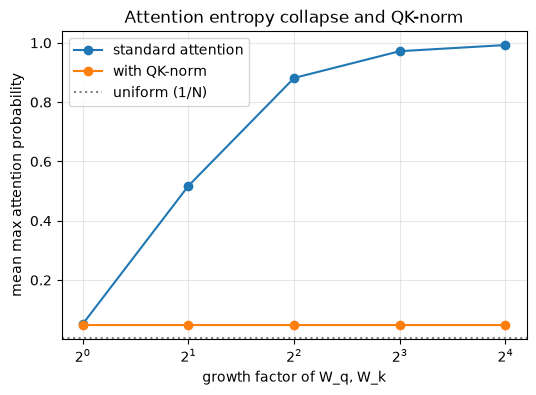

In [9]:
class QKNormAttention(Attention):
    def __init__(self, dim, num_heads=8, **kwargs):
        super().__init__(dim, num_heads, **kwargs)
        self.q_norm = nn.LayerNorm(self.head_dim)
        self.k_norm = nn.LayerNorm(self.head_dim)

    def forward(self, x, return_attn=False):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4).unbind(0)
        q, k = self.q_norm(q), self.k_norm(k)
        attn = ((q @ k.transpose(-2, -1)) * self.scale).softmax(-1)
        out = self.proj((attn @ v).transpose(1, 2).reshape(B, N, C))
        return (out, attn) if return_attn else out


def mean_max_attention(attn_module, x, growth):
    """Scale the q/k projection weights by `growth` and return the average max attention probability."""
    attn_module = copy.deepcopy(attn_module)
    D = x.shape[-1]
    with torch.no_grad():
        attn_module.qkv.weight[:2 * D] *= growth          # rows of W_q and W_k
    if isinstance(attn_module, QKNormAttention):
        _, attn = attn_module(x, return_attn=True)
    else:
        attn_module.store_attn = True
        attn_module(x)
        attn = attn_module.attn_map
    return attn.max(-1).values.mean().item()


torch.manual_seed(0)
x = torch.randn(4, 197, 384)
plain = Attention(384, 6)
nn.init.normal_(plain.qkv.weight, std=384 ** -0.5)            # unit-variance q, k at "growth = 1"
qknorm = QKNormAttention(384, 6)
qknorm.qkv.weight.data.copy_(plain.qkv.weight.data)

growths = [1, 2, 4, 8, 16]
plt.figure(figsize=(6, 4))
plt.plot(growths, [mean_max_attention(plain, x, g) for g in growths], marker="o", label="standard attention")
plt.plot(growths, [mean_max_attention(qknorm, x, g) for g in growths], marker="o", label="with QK-norm")
plt.axhline(1 / 197, color="gray", ls=":", label="uniform (1/N)")
plt.xscale("log", base=2)
plt.xlabel("growth factor of W_q, W_k"); plt.ylabel("mean max attention probability")
plt.title("Attention entropy collapse and QK-norm")
plt.grid(alpha=0.3); plt.legend()
plt.show()

<a id='Positions'></a>
# Positional information and extra tokens

Absolute learned positional embeddings have two practical problems: they must be **interpolated** when the resolution changes (and interpolation hurts at large ratios), and they are **absolute**, while for images what matters is mostly *relative* position ("the eye is above the nose"). Three popular alternatives:

## 1. Conditional Positional Encoding (CPVT): position from a convolution

A **Positional Encoding Generator (PEG)** reshapes patch tokens back into a 2D map, applies a $3 \times 3$ **depthwise convolution** and adds the result:

$$
\mathbf{X} \leftarrow \mathbf{X} + \mathrm{DWConv}_{3 \times 3}(\mathbf{X}).
$$

The convolution sees the local neighbourhood (relative position), and zero padding at the borders leaks *absolute* position. It works for any resolution with no interpolation. PVTv2, Twins and many hybrids use this idea (often inside the MLP).

In [10]:
class PEG(nn.Module):
    """Positional Encoding Generator (CPVT): depthwise 3x3 conv over the 2D token map."""

    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim)

    def forward(self, x, H, W):          # x: (B, N=H*W, C) patch tokens
        feat = rearrange(x, "b (h w) c -> b c h w", h=H, w=W)
        return x + rearrange(self.proj(feat), "b c h w -> b (h w) c")


peg = PEG(192)
for grid in [7, 14, 24]:
    tokens = torch.randn(2, grid * grid, 192)
    print(f"grid {grid}x{grid}: {tuple(peg(tokens, grid, grid).shape)}  -- no interpolation needed")

# PEG breaks permutation equivariance: shuffling tokens changes the result beyond a permutation
tokens = torch.randn(1, 49, 192)
perm = torch.randperm(49)
print("equivariant after PEG?", torch.allclose(peg(tokens[:, perm], 7, 7), peg(tokens, 7, 7)[:, perm], atol=1e-5))

grid 7x7: (2, 49, 192)  -- no interpolation needed
grid 14x14: (2, 196, 192)  -- no interpolation needed
grid 24x24: (2, 576, 192)  -- no interpolation needed
equivariant after PEG? False


## 2. Rotary Position Embedding (RoPE) in 2D

RoPE does not add anything to the tokens. Instead it **rotates** queries and keys: pairs of channels $(q_{2i}, q_{2i+1})$ are rotated by an angle $\theta_i \cdot p$ proportional to the position $p$:

$$
\mathrm{RoPE}(\mathbf{q}, p) = \mathbf{R}_{p}\, \mathbf{q}, \qquad \mathbf{R}_p = \mathrm{blockdiag}\left( \begin{bmatrix} \cos p\theta_i & -\sin p\theta_i \\ \sin p\theta_i & \cos p\theta_i \end{bmatrix} \right)_i .
$$

Because rotations compose, $\langle \mathbf{R}_m \mathbf{q}, \mathbf{R}_n \mathbf{k} \rangle = \langle \mathbf{q}, \mathbf{R}_{n-m} \mathbf{k} \rangle$: the attention score depends only on the **relative** offset $n - m$. For images ("axial" 2D RoPE) half of the channel pairs rotate with the $x$ coordinate and half with $y$. RoPE extrapolates to new resolutions gracefully and is used in EVA-02, RoPE-ViT, DINOv3, Perception Encoder and SAM 3.

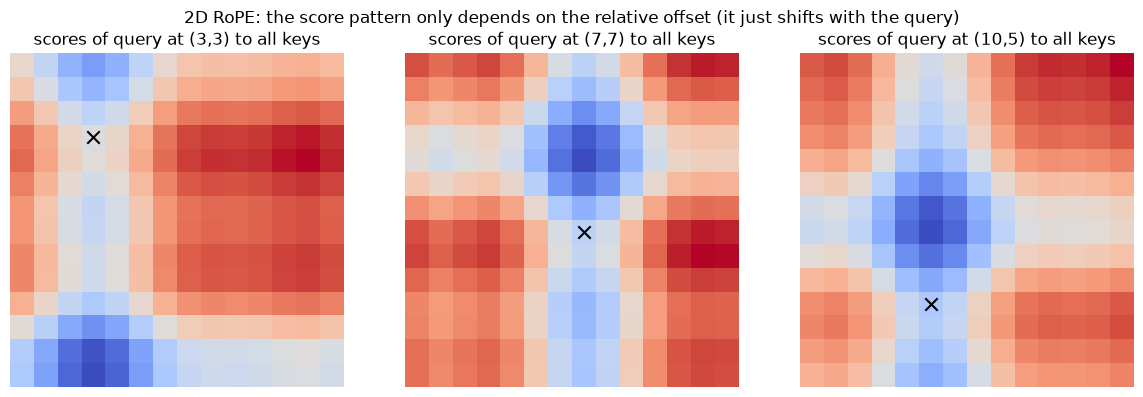

score(q@(3,3), k@(5,8)) = 3.329089403152466 | score(q@(5,7), k@(7,12)) = 3.3290884494781494


In [11]:
def rope_2d_angles(grid_h, grid_w, head_dim, base=100.0):
    """Axial 2D RoPE angles: (N, head_dim // 2). First half of the pairs encodes x, second half encodes y."""
    n_freqs = head_dim // 4
    freqs = 1.0 / base ** (torch.arange(n_freqs).float() / n_freqs)
    ys, xs = torch.meshgrid(torch.arange(grid_h).float(), torch.arange(grid_w).float(), indexing="ij")
    return torch.cat([xs.flatten()[:, None] * freqs, ys.flatten()[:, None] * freqs], dim=-1)


def apply_rope(x, angles):
    """Rotate channel pairs (x_{2i}, x_{2i+1}) by `angles`. x: (..., N, d), angles: (N, d/2)"""
    x1, x2 = x[..., 0::2], x[..., 1::2]
    cos, sin = angles.cos(), angles.sin()
    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).flatten(-2)


G, d = 14, 64
angles = rope_2d_angles(G, G, d)
q = torch.randn(d).expand(G * G, d)    # the SAME query content at every position
k = torch.randn(d).expand(G * G, d)    # the SAME key content at every position
scores = apply_rope(q, angles) @ apply_rope(k, angles).T   # (N, N)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (r, c) in zip(axes, [(3, 3), (7, 7), (10, 5)]):
    ax.imshow(scores[r * G + c].reshape(G, G), cmap="coolwarm")
    ax.scatter([c], [r], marker="x", color="black", s=80)
    ax.set_title(f"scores of query at ({r},{c}) to all keys")
    ax.axis("off")
plt.suptitle("2D RoPE: the score pattern only depends on the relative offset (it just shifts with the query)")
plt.tight_layout()
plt.show()

# Numerical check of the relative property: shift both query and key positions by the same offset
i, j, di = 3 * G + 3, 5 * G + 8, 2 * G + 4
print("score(q@(3,3), k@(5,8)) =", scores[i, j].item(), "| score(q@(5,7), k@(7,12)) =", scores[i + di, j + di].item())

## 3. Registers: extra tokens with no image content

Darcet et al. (2023) noticed that large, well-trained ViTs (supervised DeiT III, OpenCLIP, DINOv2) produce **high-norm "artifact" tokens** in low-information background regions. The model *recycles* these redundant patches as a global scratch-pad memory: they hold global information and drop their local content, which spoils attention maps and dense features.

The fix is trivial: append a few (e.g. 4) extra learnable **register** tokens, like [CLS], and discard them at the output. The model now has a dedicated place for global computation and the artifacts disappear.

Let's reproduce this with DINOv2 ViT-B/14 **with** and **without** registers: we look at the norm of every patch token in the 10th block.

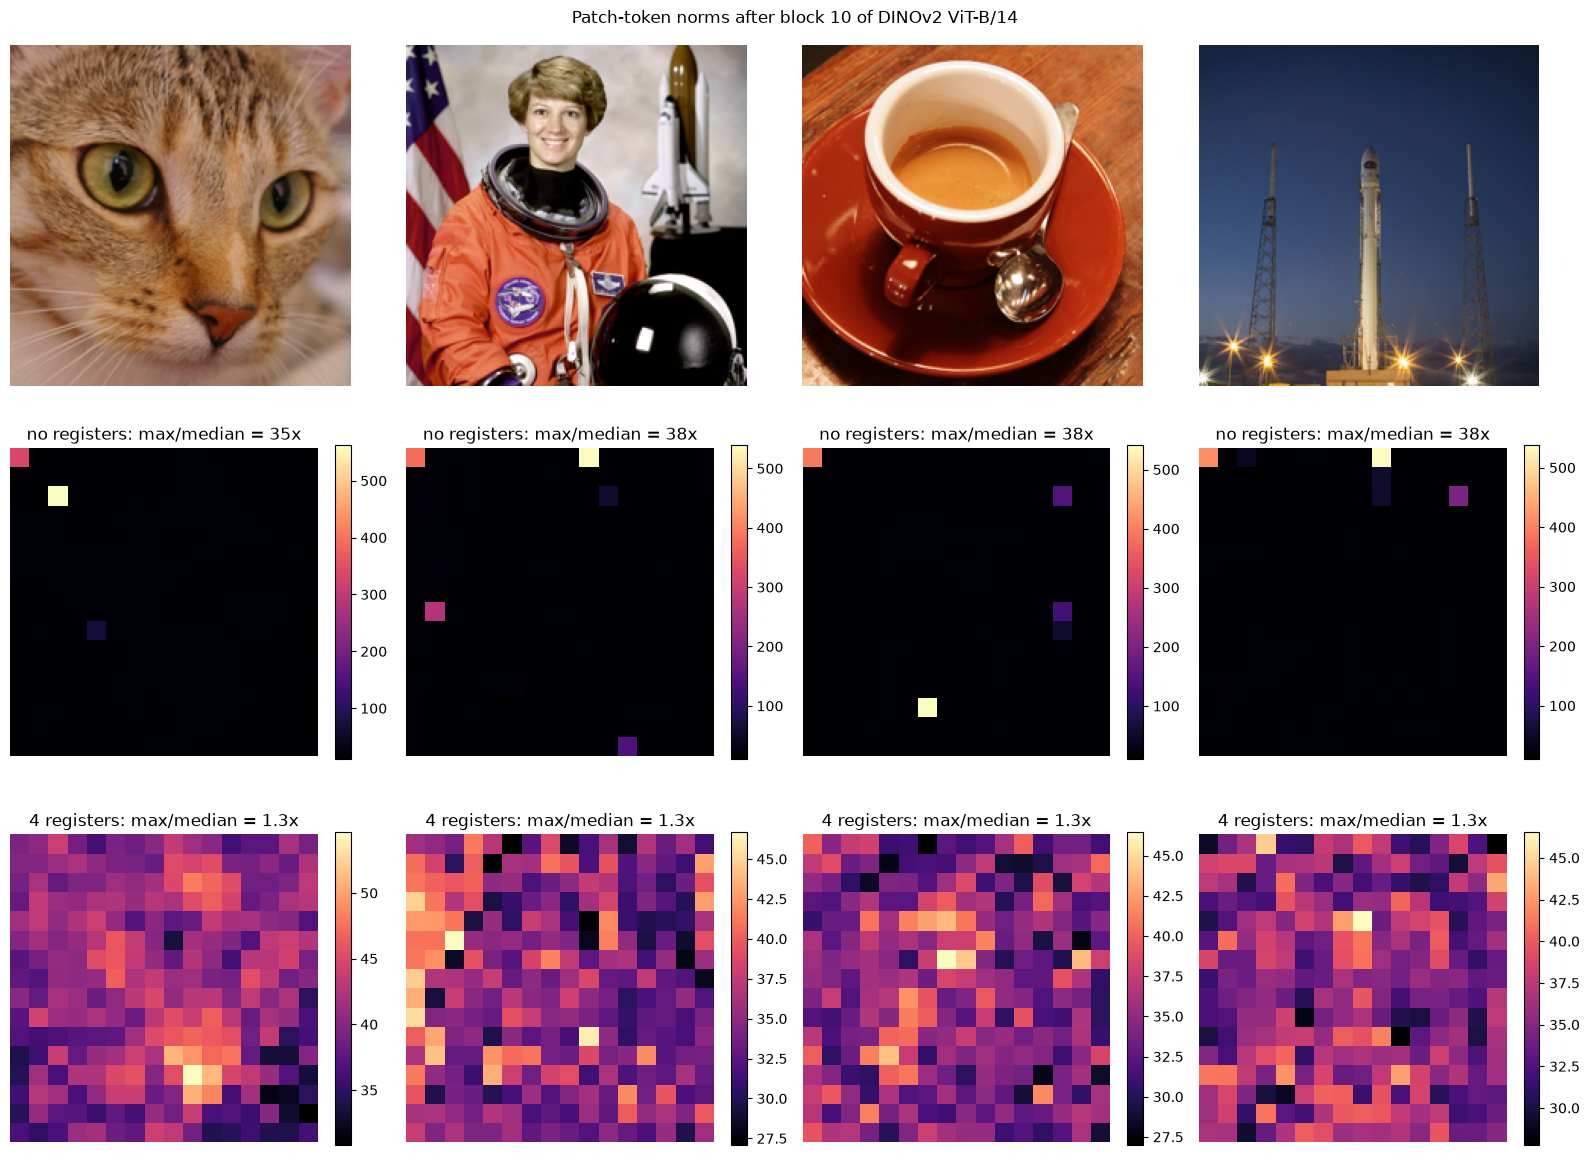

In [12]:
def token_norms(model, x, block_idx):
    """Norms of patch tokens (prefix tokens removed) after block `block_idx`."""
    with torch.no_grad():
        z = model.norm_pre(model._pos_embed(model.patch_embed(x)))
        for blk in model.blocks[:block_idx + 1]:
            z = blk(z)
    patch = z[:, model.num_prefix_tokens:]
    g = int(math.sqrt(patch.shape[1]))
    return patch.norm(dim=-1).reshape(-1, g, g)


dinov2 = timm.create_model("vit_base_patch14_dinov2.lvd142m", pretrained=True, img_size=224).eval()
dinov2_reg = timm.create_model("vit_base_patch14_reg4_dinov2.lvd142m", pretrained=True, img_size=224).eval()
x_nat, mean, std = preprocess_for(dinov2, natural_images.values(), size=224)

norms = token_norms(dinov2, x_nat, block_idx=9)
norms_reg = token_norms(dinov2_reg, x_nat, block_idx=9)

fig, axes = plt.subplots(3, len(natural_images), figsize=(4 * len(natural_images), 12))
for i in range(len(natural_images)):
    axes[0, i].imshow(denormalize(x_nat[i], mean, std)); axes[0, i].axis("off")
    im = axes[1, i].imshow(norms[i], cmap="magma"); axes[1, i].axis("off"); plt.colorbar(im, ax=axes[1, i], fraction=0.046)
    axes[1, i].set_title(f"no registers: max/median = {norms[i].max() / norms[i].median():.0f}x")
    im = axes[2, i].imshow(norms_reg[i], cmap="magma"); axes[2, i].axis("off"); plt.colorbar(im, ax=axes[2, i], fraction=0.046)
    axes[2, i].set_title(f"4 registers: max/median = {norms_reg[i].max() / norms_reg[i].median():.1f}x")
plt.suptitle("Patch-token norms after block 10 of DINOv2 ViT-B/14")
plt.tight_layout()
plt.show()

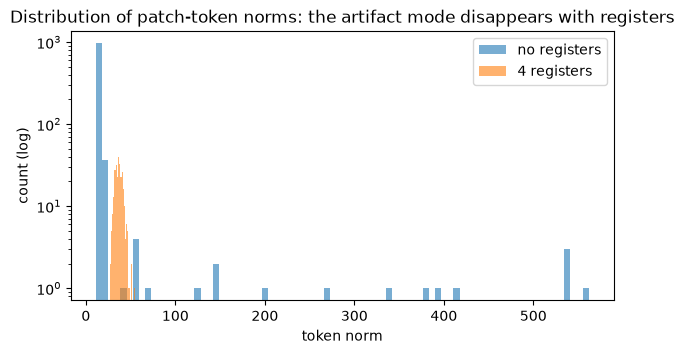

In [13]:
plt.figure(figsize=(7, 3.5))
plt.hist(norms.flatten().numpy(), bins=80, alpha=0.6, label="no registers", log=True)
plt.hist(norms_reg.flatten().numpy(), bins=80, alpha=0.6, label="4 registers", log=True)
plt.xlabel("token norm"); plt.ylabel("count (log)"); plt.legend()
plt.title("Distribution of patch-token norms: the artifact mode disappears with registers")
plt.show()
del dinov2, dinov2_reg

Without registers a handful of patches — mostly in uninformative background regions (see the subplot titles for the max/median ratio in this run) — have norms more than an order of magnitude above the median and form a separate mode of the histogram. With registers the outliers are gone. Registers are now standard in large vision encoders (DINOv2-reg, DINOv3).

## 4. Flexible resolution and patch size: FlexiViT and NaViT

Real images come in different resolutions and aspect ratios, while the classic recipe *resizes (and crops) everything to a fixed square*. Two ideas make ViTs flexible:

**FlexiViT (Beyer et al., 2023): resize the patch embedding.** Suppose we want to run a model trained with $P=16$ on $448 \times 448$ images with $P = 32$, keeping the same $14 \times 14$ token grid. Every new patch $\mathbf{x}'$ is (approximately) the old patch upsampled, $\mathbf{x}' = \mathbf{B}\mathbf{x}$, where $\mathbf{B}$ is the linear resize operator. We want new kernels $\mathbf{w}'$ that give the **same tokens**: $\langle \mathbf{B}\mathbf{x}, \mathbf{w}' \rangle = \langle \mathbf{x}, \mathbf{w} \rangle$ for all $\mathbf{x}$. The least-squares solution is the **pseudo-inverse resize** (PI-resize):

$$
\mathbf{w}' = (\mathbf{B}^\top)^{+}\, \mathbf{w}.
$$

Naively resizing the kernel like an image ($\mathbf{w}' = \mathbf{B}\mathbf{w}$) changes the token statistics (e.g. the dot product now sums over 4x more pixels). FlexiViT additionally *trains* with a randomly sampled patch size, so one model can trade accuracy for speed at inference time. `timm` implements PI-resize in `timm.layers.resample_patch_embed`.

**NaViT (Dehghani et al., 2023): "Patch n' Pack".** Instead of resizing images to a square, keep the native resolution and aspect ratio, cut each image into its own number of patches, and **pack** the token sequences of several images into one long sequence with an attention mask that blocks attention across images (plus factorized 2D positional embeddings). SigLIP 2 NaFlex is a recent example of this idea.

Let's check the FlexiViT argument numerically: run ViT-S/16 on upsampled $448 \times 448$ images with a $32 \times 32$ patch embedding obtained by naive vs PI resizing.

In [14]:
from timm.layers import resample_patch_embed

vit_s_in1k = timm.create_model("vit_small_patch16_224.augreg_in1k", pretrained=True).eval()
state_dict = vit_s_in1k.state_dict()
w16 = state_dict["patch_embed.proj.weight"]                                             # (384, 3, 16, 16)

w32_naive = F.interpolate(w16, size=(32, 32), mode="bicubic", align_corners=False)     # resize the kernel like an image
w32_pi = resample_patch_embed(w16, new_size=[32, 32], interpolation="bicubic", antialias=False)


def vit_with_patch_embed(weight, img_size, patch_size):
    model = VisionTransformer(img_size=img_size, patch_size=patch_size, embed_dim=384, depth=12, num_heads=6)
    model.load_state_dict({**state_dict, "patch_embed.proj.weight": weight}, strict=True)
    return model.eval().to(DEVICE)


upsample = lambda x: F.interpolate(x, size=(448, 448), mode="bicubic", align_corners=False)
x_nat, _, _ = preprocess_for(vit_s_in1k, natural_images.values())
with torch.no_grad():
    tokens_ref = vit_with_patch_embed(w16, 224, 16).patch_embed(x_nat.to(DEVICE))
    for name, w in [("naive kernel resize", w32_naive), ("PI-resize", w32_pi)]:
        tokens = vit_with_patch_embed(w, 448, 32).patch_embed(upsample(x_nat).to(DEVICE))
        cos = F.cosine_similarity(tokens, tokens_ref, dim=-1).mean().item()
        print(f"{name:<20} token norm ratio: {(tokens.norm(dim=-1) / tokens_ref.norm(dim=-1)).mean():.2f} | "
              f"cosine to original tokens: {cos:.3f}")

woof_loader_vit = make_eval_loader(IMAGEWOOF_VAL, vit_s_in1k, batch_size=64, num_workers=NUM_WORKERS)
flexi_rows = []
for name, w, size, patch, fwd_input in [
    ("P=16 @224 (original)", w16, 224, 16, lambda x: x),
    ("P=32 @448, naive kernel resize", w32_naive, 448, 32, upsample),
    ("P=32 @448, PI-resize", w32_pi, 448, 32, upsample),
]:
    model = vit_with_patch_embed(w, size, patch)
    acc = evaluate_on_imagenet_subset(model, woof_loader_vit, DEVICE, forward_fn=lambda x: model(fwd_input(x)))
    flexi_rows.append({"setting": name, **acc})
pd.DataFrame(flexi_rows).round(4)

naive kernel resize  token norm ratio: 3.27 | cosine to original tokens: 0.897


PI-resize            token norm ratio: 1.00 | cosine to original tokens: 1.000


,setting,top1_subset,top1_imagenet
0,P=16 @224 (original),0.9766,0.8651
1,"P=32 @448, naive kernel resize",0.8593,0.5515
2,"P=32 @448, PI-resize",0.9766,0.8649


<a id='Hierarchical'></a>
# Hierarchical transformers: PVT and Swin

<img src="https://raw.githubusercontent.com/microsoft/Swin-Transformer/main/figures/teaser.png" width="600">

CNNs produce a **feature pyramid**: resolution $1/4 \rightarrow 1/8 \rightarrow 1/16 \rightarrow 1/32$ while channels grow. Detection and segmentation heads (FPN, UPerNet, Mask R-CNN) are built around such pyramids. A plain ViT has a single $1/16$ map.

Hierarchical transformers bring the pyramid back:
* start with **small patches** ($4 \times 4$ $\Rightarrow$ $56 \times 56$ tokens for 224px);
* after each stage **merge** neighbouring tokens ($2 \times 2 \rightarrow 1$) and increase channels;
* make attention affordable at the high-resolution stages.

The two canonical ways to make early-stage attention affordable are **spatial-reduction attention** (PVT) and **window attention** (Swin).

## PVT: Spatial-Reduction Attention (SRA)

Queries stay at full resolution, but keys and values are computed from a map downsampled by a strided convolution with ratio $R$:

$$
\mathrm{SRA}(\mathbf{Q}, \mathbf{K}, \mathbf{V}) = \mathrm{Attention}\big(\mathbf{Q}\mathbf{W}_Q,\ \mathrm{SR}(\mathbf{K})\mathbf{W}_K,\ \mathrm{SR}(\mathbf{V})\mathbf{W}_V\big), \qquad \text{cost } \mathcal{O}\!\left(\frac{N^2}{R^2}\right).
$$

Every query still sees the **whole image** (global receptive field), just at a coarser resolution. Note that SRA is still **quadratic** in $N$ — only with an $R^2$ smaller constant ($R = 8, 4, 2, 1$ in the four stages of PVT). PVTv2 adds a "linear SRA" variant that pools keys/values to a fixed $7 \times 7$ size.

In [20]:
class SpatialReductionAttention(nn.Module):
    def __init__(self, dim, num_heads, sr_ratio=1):
        super().__init__()
        self.num_heads, self.head_dim = num_heads, dim // num_heads
        self.q = nn.Linear(dim, dim)
        self.kv = nn.Linear(dim, dim * 2)
        self.proj = nn.Linear(dim, dim)
        self.sr_ratio = sr_ratio
        if sr_ratio > 1:
            self.sr = nn.Conv2d(dim, dim, kernel_size=sr_ratio, stride=sr_ratio)
            self.norm = nn.LayerNorm(dim)

    def forward(self, x, H, W):
        B, N, C = x.shape
        q = rearrange(self.q(x), "b n (h d) -> b h n d", h=self.num_heads)
        if self.sr_ratio > 1:
            x = rearrange(x, "b (h w) c -> b c h w", h=H, w=W)
            x = self.norm(rearrange(self.sr(x), "b c h w -> b (h w) c"))   # N / R^2 tokens
        k, v = rearrange(self.kv(x), "b n (two h d) -> two b h n d", two=2, h=self.num_heads)
        out = F.scaled_dot_product_attention(q, k, v)
        return self.proj(rearrange(out, "b h n d -> b n (h d)")), k.shape[2]


sra = SpatialReductionAttention(dim=64, num_heads=1, sr_ratio=8)
out, n_kv = sra(torch.randn(1, 56 * 56, 64), 56, 56)
print(f"queries: {56 * 56} tokens, keys/values: {n_kv} tokens -> attention matrix {56 * 56}x{n_kv} "
      f"instead of {56 * 56}x{56 * 56} ({(56 * 56) / n_kv:.0f}x smaller)")

queries: 3136 tokens, keys/values: 49 tokens -> attention matrix 3136x49 instead of 3136x3136 (64x smaller)


## Swin Transformer: (shifted) window attention

Swin computes self-attention only **inside non-overlapping windows** of $M \times M$ tokens ($M = 7$). For a map of $h \times w$ tokens with $C$ channels:

$$
\Omega(\text{MSA}) = 4hwC^2 + 2(hw)^2C, \qquad \Omega(\text{W-MSA}) = 4hwC^2 + 2M^2hwC.
$$

Window attention is **linear** in the number of tokens. But windows do not talk to each other. The fix is to alternate two kinds of blocks:

1. **W-MSA:** regular window partition;
2. **SW-MSA:** the partition is **shifted** by $(\lfloor M/2 \rfloor, \lfloor M/2 \rfloor)$ tokens, so new windows straddle the old borders and information flows between neighbouring windows.

A naive shifted partition creates more (and smaller) windows. Swin's trick: **cyclically roll** the feature map by $-M/2$, so the number of windows stays the same, and use an **attention mask** that forbids attention between tokens that came from different (non-adjacent) regions.

Finally, instead of absolute positions Swin adds a learned **relative position bias** $B \in \mathbb{R}^{M^2 \times M^2}$ (parameterized by a table of $(2M-1)^2$ values per head) to the attention logits:
$\mathrm{softmax}(\mathbf{Q}\mathbf{K}^\top / \sqrt{d} + B)\mathbf{V}$.

Let's implement all of it.

In [21]:
def window_partition(x, ws):
    """(B, H, W, C) -> (B * num_windows, ws * ws, C)"""
    return rearrange(x, "b (nh wh) (nw ww) c -> (b nh nw) (wh ww) c", wh=ws, ww=ws)


def window_reverse(windows, ws, H, W):
    """(B * num_windows, ws * ws, C) -> (B, H, W, C)"""
    return rearrange(windows, "(b nh nw) (wh ww) c -> b (nh wh) (nw ww) c", nh=H // ws, nw=W // ws, wh=ws, ww=ws)


def shifted_window_attn_mask(H, W, ws, shift):
    """(num_windows, ws*ws, ws*ws) additive mask: 0 inside the same region, -100 across regions."""
    region = torch.zeros(1, H, W, 1)
    cnt = 0
    for hs in (slice(0, -ws), slice(-ws, -shift), slice(-shift, None)):
        for wsl in (slice(0, -ws), slice(-ws, -shift), slice(-shift, None)):
            region[:, hs, wsl, :] = cnt
            cnt += 1
    region_windows = window_partition(region, ws).squeeze(-1)           # (nW, ws*ws)
    mask = region_windows[:, None, :] - region_windows[:, :, None]      # != 0 -> different regions
    return mask.masked_fill(mask != 0, -100.0).masked_fill(mask == 0, 0.0), region[0, :, :, 0]


def relative_position_index(ws):
    """(ws*ws, ws*ws) index into a ((2ws-1)^2, heads) bias table."""
    coords = torch.stack(torch.meshgrid(torch.arange(ws), torch.arange(ws), indexing="ij")).flatten(1)  # (2, ws*ws)
    rel = (coords[:, :, None] - coords[:, None, :]).permute(1, 2, 0)                                  # (N, N, 2)
    rel[:, :, 0] += ws - 1
    rel[:, :, 1] += ws - 1
    rel[:, :, 0] *= 2 * ws - 1
    return rel.sum(-1)

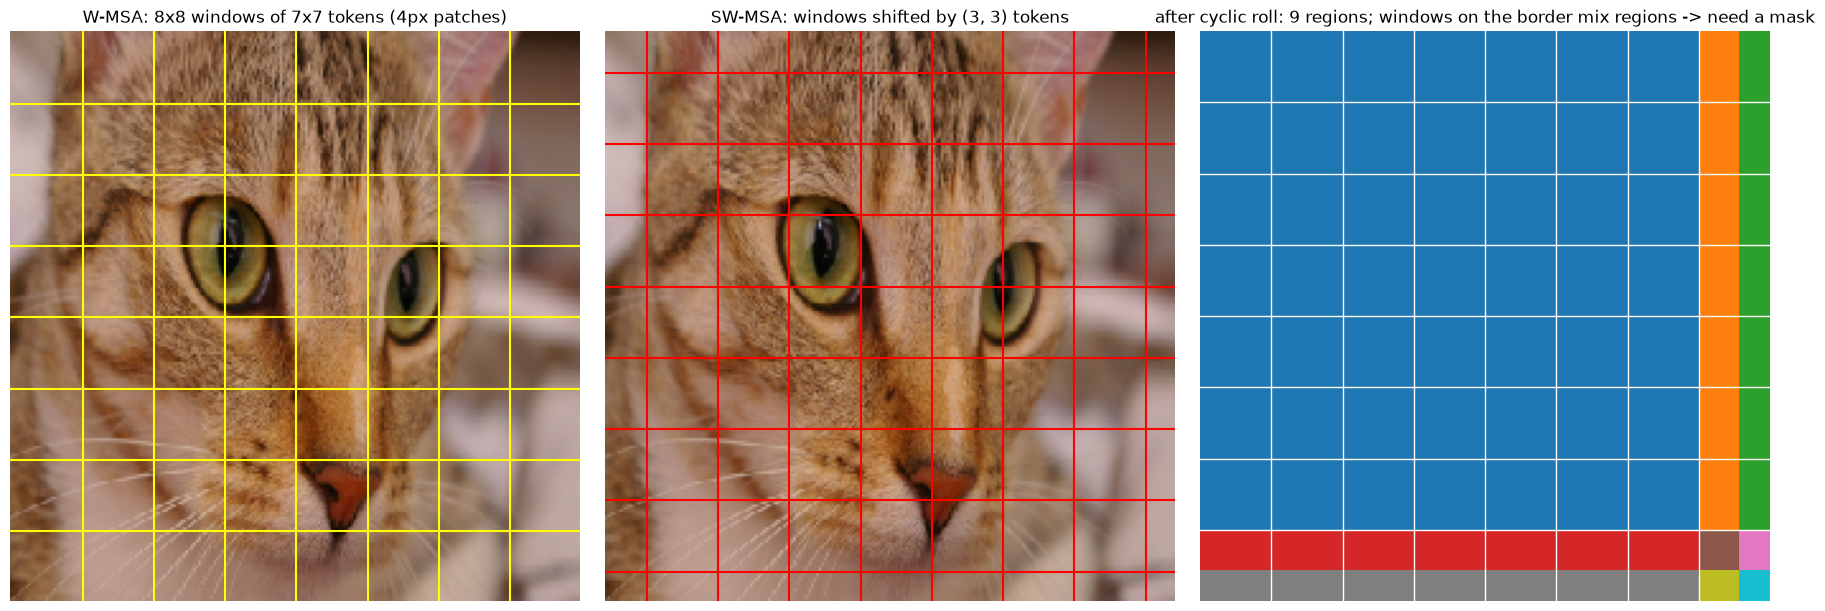

In [22]:
# Visualize: regular windows, shifted windows, and the cyclic-shift trick on a 56x56 token map (stage 1 of Swin-T)
H = W = 56
ws, shift = 7, 3
img = F.interpolate(torch.from_numpy(skdata.chelsea()).permute(2, 0, 1)[None].float() / 255, size=(224, 224))[0].permute(1, 2, 0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(img)
for k in range(1, H // ws):
    axes[0].axhline(k * ws * 4, color="yellow", lw=1.5); axes[0].axvline(k * ws * 4, color="yellow", lw=1.5)
axes[0].set_title("W-MSA: 8x8 windows of 7x7 tokens (4px patches)")

axes[1].imshow(img)
for k in range(0, H // ws):
    axes[1].axhline((k * ws + ws - shift) * 4, color="red", lw=1.5); axes[1].axvline((k * ws + ws - shift) * 4, color="red", lw=1.5)
axes[1].set_title("SW-MSA: windows shifted by (3, 3) tokens")

_, regions = shifted_window_attn_mask(H, W, ws, shift)
axes[2].imshow(regions, cmap="tab10")
for k in range(1, H // ws):
    axes[2].axhline(k * ws - 0.5, color="white", lw=1); axes[2].axvline(k * ws - 0.5, color="white", lw=1)
axes[2].set_title("after cyclic roll: 9 regions; windows on the border mix regions -> need a mask")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

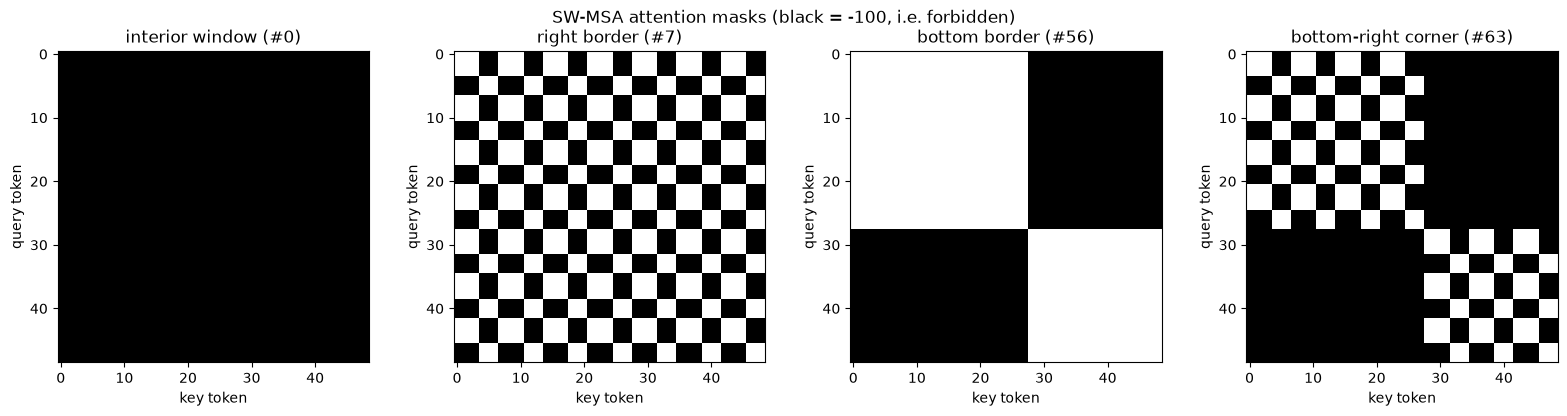

In [23]:
masks, _ = shifted_window_attn_mask(H, W, ws, shift)
n_win = H // ws
picks = {"interior window": 0, "right border": n_win - 1, "bottom border": n_win * (n_win - 1), "bottom-right corner": n_win * n_win - 1}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, idx) in zip(axes, picks.items()):
    ax.imshow(masks[idx], cmap="gray")
    ax.set_title(f"{name} (#{idx})")
    ax.set_xlabel("key token"); ax.set_ylabel("query token")
plt.suptitle("SW-MSA attention masks (black = -100, i.e. forbidden)")
plt.tight_layout()
plt.show()

In [24]:
class WindowAttention(nn.Module):
    def __init__(self, dim, num_heads, window_size):
        super().__init__()
        self.num_heads, self.window_size = num_heads, window_size
        self.scale = (dim // num_heads) ** -0.5
        self.relative_position_bias_table = nn.Parameter(torch.zeros((2 * window_size - 1) ** 2, num_heads))
        self.register_buffer("relative_position_index", relative_position_index(window_size), persistent=False)
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x, mask=None):                 # x: (B * nW, M*M, C)
        Bw, N, C = x.shape
        q, k, v = rearrange(self.qkv(x), "b n (three h d) -> three b h n d", three=3, h=self.num_heads)
        attn = (q @ k.transpose(-2, -1)) * self.scale
        bias = self.relative_position_bias_table[self.relative_position_index.view(-1)].view(N, N, -1)
        attn = attn + bias.permute(2, 0, 1)[None]     # (1, h, N, N)
        if mask is not None:                          # mask: (nW, N, N)
            nW = mask.shape[0]
            attn = attn.view(Bw // nW, nW, self.num_heads, N, N) + mask[None, :, None]
            attn = attn.view(Bw, self.num_heads, N, N)
        x = attn.softmax(-1) @ v
        return self.proj(rearrange(x, "b h n d -> b n (h d)"))


class SwinBlock(nn.Module):
    def __init__(self, dim, num_heads, input_resolution, window_size=7, shift_size=0, mlp_ratio=4.0):
        super().__init__()
        self.H, self.W = input_resolution
        self.window_size, self.shift_size = window_size, shift_size
        self.norm1 = nn.LayerNorm(dim)
        self.attn = WindowAttention(dim, num_heads, window_size)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential()
        self.mlp.fc1, self.mlp.act, self.mlp.fc2 = nn.Linear(dim, int(dim * mlp_ratio)), nn.GELU(), nn.Linear(int(dim * mlp_ratio), dim)
        mask = shifted_window_attn_mask(self.H, self.W, window_size, shift_size)[0] if shift_size > 0 else None
        self.register_buffer("attn_mask", mask, persistent=False)

    def forward(self, x):                             # x: (B, H, W, C)
        B, H, W, C = x.shape
        shortcut = x
        x = self.norm1(x)
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(-self.shift_size, -self.shift_size), dims=(1, 2))
        x = window_partition(x, self.window_size)
        x = self.attn(x, mask=self.attn_mask)
        x = window_reverse(x, self.window_size, H, W)
        if self.shift_size > 0:
            x = torch.roll(x, shifts=(self.shift_size, self.shift_size), dims=(1, 2))
        x = shortcut + x
        return x + self.mlp(self.norm2(x))


class PatchMerging(nn.Module):
    """Downsample 2x: concatenate 2x2 neighbouring tokens (4C) and project to 2C."""

    def __init__(self, dim):
        super().__init__()
        self.norm = nn.LayerNorm(4 * dim)
        self.reduction = nn.Linear(4 * dim, 2 * dim, bias=False)

    def forward(self, x):                             # (B, H, W, C) -> (B, H/2, W/2, 2C)
        x = rearrange(x, "b (h s1) (w s2) c -> b h w (s2 s1 c)", s1=2, s2=2)
        return self.reduction(self.norm(x))

Verification against the official weights: we load stage 1 of `swin_tiny_patch4_window7_224` (a W-MSA block, a SW-MSA block and the first patch merging) into our modules and compare the outputs with `timm`.

In [25]:
timm_swin = timm.create_model("swin_tiny_patch4_window7_224.ms_in1k", pretrained=True).eval()
our_blocks = nn.Sequential(
    SwinBlock(96, 3, (56, 56), window_size=7, shift_size=0),
    SwinBlock(96, 3, (56, 56), window_size=7, shift_size=3),
)
for ours, theirs in zip(our_blocks, timm_swin.layers[0].blocks):
    print(ours.load_state_dict(theirs.state_dict(), strict=True))
our_merge = PatchMerging(96)
print(our_merge.load_state_dict(timm_swin.layers[1].downsample.state_dict(), strict=True))

x_img, _, _ = preprocess_for(timm_swin, natural_images.values())
with torch.no_grad():
    tokens = timm_swin.patch_embed(x_img)                  # (B, 56, 56, 96)
    ref = timm_swin.layers[1].downsample(timm_swin.layers[0](tokens))
    ours = our_merge(our_blocks(tokens))
print("stage-1 output:", tuple(ours.shape), "| max |timm - ours| =", (ref - ours).abs().max().item())

<All keys matched successfully>
<All keys matched successfully>
<All keys matched successfully>


stage-1 output: (4, 28, 28, 192) | max |timm - ours| = 2.9578804969787598e-06


In [26]:
# The pyramid: hierarchical Swin vs plain ViT feature maps for a 224x224 image
swin_feats = timm.create_model("swin_tiny_patch4_window7_224", features_only=True)(torch.randn(1, 3, 224, 224))
vit_s = timm.create_model("vit_small_patch16_224")
vit_feats = vit_s.forward_intermediates(torch.randn(1, 3, 224, 224), indices=[2, 5, 8, 11], intermediates_only=True)
pd.DataFrame({
    "stage": [1, 2, 3, 4],
    "Swin-T (NHWC)": [tuple(f.shape) for f in swin_feats],
    "Swin-T stride": [224 // f.shape[1] for f in swin_feats],
    "ViT-S/16 (NCHW)": [tuple(f.shape) for f in vit_feats],
    "ViT-S/16 stride": [224 // f.shape[-1] for f in vit_feats],
})

,stage,Swin-T (NHWC),Swin-T stride,ViT-S/16 (NCHW),ViT-S/16 stride
0,1,"(1, 56, 56, 96)",4,"(1, 384, 14, 14)",16
1,2,"(1, 28, 28, 192)",8,"(1, 384, 14, 14)",16
2,3,"(1, 14, 14, 384)",16,"(1, 384, 14, 14)",16
3,4,"(1, 7, 7, 768)",32,"(1, 384, 14, 14)",16


### Other hierarchical designs
* **Swin V2**: scaled cosine attention (instead of dot product) and log-spaced continuous relative position bias — for training stability at 3B parameters and transfer to large windows/resolutions.
* **MViT / MViTv2**: pooling attention (pool Q, K, V) with channel expansion — strong for video.
* **Hiera**: a hierarchical ViT with **no** bells and whistles (no relative bias, no shifted windows, no convs) that recovers spatial biases from **MAE pre-training**; very fast. Used as the backbone of SAM 2.

<a id='Efficient_Attention'></a>
# Efficient attention

| Family | Idea | Complexity | Examples |
|---|---|---|---|
| **Local / sparse patterns** | attend within windows, along axes, or on a dilated grid | $\mathcal{O}(N M^2)$ | Swin, MaxViT (window + grid), axial attention, NAT |
| **Reduced K/V** | downsample or project keys/values | $\mathcal{O}(N N / R^2)$ or $\mathcal{O}(N k)$ | PVT (SRA), Linformer, SegFormer |
| **Kernelized / linear** | replace $\mathrm{softmax}(\mathbf{Q}\mathbf{K}^\top)$ by $\phi(\mathbf{Q})\phi(\mathbf{K})^\top$ and use associativity | $\mathcal{O}(N d^2)$ | Linear Transformer, Performer, EfficientViT |
| **IO-aware exact attention** | never write the $N \times N$ matrix to HBM, tile in SRAM | $\mathcal{O}(N^2)$ compute, $\mathcal{O}(N)$ memory | FlashAttention 1/2/3, `F.scaled_dot_product_attention` |
| **Fewer tokens** | drop or merge redundant tokens during the forward | fewer $N$ in later layers | DynamicViT, EViT, **ToMe** |
| **Not attention at all** | state-space models / linear RNNs scanning the patch sequence | $\mathcal{O}(N)$ | Vision Mamba, VMamba, Vision-RWKV (2024; no clear win over ViTs at scale so far) |

We already met windows (Swin), reduced K/V (PVT) and fused kernels (Lecture 1). Kernelized **linear attention** is implemented and benchmarked in [Appendix A](#Appendix). Here we look at the most practical "fewer tokens" method.

## Token Merging (ToMe)

Many patch tokens are redundant (sky, wall, background). **ToMe** gradually **merges** similar tokens *inside* a pretrained ViT, with **no re-training**:

1. In each block, after attention, split tokens into two alternating sets $\mathcal{A}$ and $\mathcal{B}$.
2. For each token in $\mathcal{A}$ find its most similar token in $\mathcal{B}$ (cosine similarity of **keys**, averaged over heads).
3. Merge the $r$ most similar pairs by a size-weighted average; the rest stay untouched. [CLS] is never merged.
4. Track the **size** $s$ (how many patches a token represents) and use **proportional attention**: $\mathrm{softmax}(\mathbf{Q}\mathbf{K}^\top/\sqrt{d} + \log \mathbf{s})$, so a merged token keeps the weight of all patches it represents.

With $r$ tokens merged per block the sequence shrinks from $N$ to $N - rL$, giving a speed-up that grows with $r$.

We implement ToMe on top of **our** ViT from Lecture 1 by swapping the classes of its attention and block modules.

In [27]:
def bipartite_soft_matching(metric, r):
    """Returns a `merge(x, mode)` function that merges r tokens. metric: (B, N, C); token 0 is [CLS] (protected)."""
    metric = metric / metric.norm(dim=-1, keepdim=True)
    a, b = metric[:, ::2], metric[:, 1::2]
    r = min(r, (metric.shape[1] - 1) // 2)
    scores = a @ b.transpose(-1, -2)
    scores[:, 0, :] = -math.inf                                     # never merge [CLS] (it sits in set A)

    node_max, node_idx = scores.max(dim=-1)                          # best match in B for every token of A
    edge_idx = node_max.argsort(dim=-1, descending=True)[..., None]
    unm_idx = edge_idx[:, r:].sort(dim=1).values                     # A tokens that stay (sorted keeps [CLS] first)
    src_idx = edge_idx[:, :r]                                        # A tokens merged into B
    dst_idx = node_idx[..., None].gather(dim=1, index=src_idx)

    def merge(x, mode="sum"):
        src, dst = x[:, ::2], x[:, 1::2]
        n, t1, c = src.shape
        unm = src.gather(dim=1, index=unm_idx.expand(n, t1 - r, c))
        src = src.gather(dim=1, index=src_idx.expand(n, r, c))
        dst = dst.scatter_reduce(1, dst_idx.expand(n, r, c), src, reduce=mode)
        return torch.cat([unm, dst], dim=1)

    return merge


class ToMeAttention(Attention):
    def forward(self, x, size):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4).unbind(0)
        # proportional attention: add log(size) of every key to the logits
        x = F.scaled_dot_product_attention(q, k, v, attn_mask=size.log()[:, None, None, :, 0].to(q.dtype))
        return self.proj(x.transpose(1, 2).reshape(B, N, C)), k.mean(1)


class ToMeBlock(Block):
    def forward(self, x, size, source=None):
        x_attn, metric = self.attn(self.norm1(x), size)
        x = x + x_attn
        if self.r > 0:
            merge = bipartite_soft_matching(metric, self.r)
            x, size = merge(x * size, "sum"), merge(size, "sum")
            x = x / size
            source = merge(source, "amax") if source is not None else None
        x = x + self.mlp(self.norm2(x))
        return x, size, source


def apply_tome(model: VisionTransformer, r: int):
    for blk in model.blocks:
        blk.__class__, blk.attn.__class__, blk.r = ToMeBlock, ToMeAttention, r
    return model


def tome_forward(model, x, track_source=False):
    x = model.patch_embed(x)
    x = torch.cat([model.cls_token.expand(x.shape[0], -1, -1), x], dim=1) + model.pos_embed
    B, N, _ = x.shape
    size = torch.ones(B, N, 1, device=x.device, dtype=x.dtype)
    source = torch.eye(N, device=x.device)[None].expand(B, N, N) if track_source else None
    for blk in model.blocks:
        x, size, source = blk(x, size, source)
    logits = model.head(model.norm(x)[:, 0])
    return (logits, source) if track_source else logits

<All keys matched successfully>


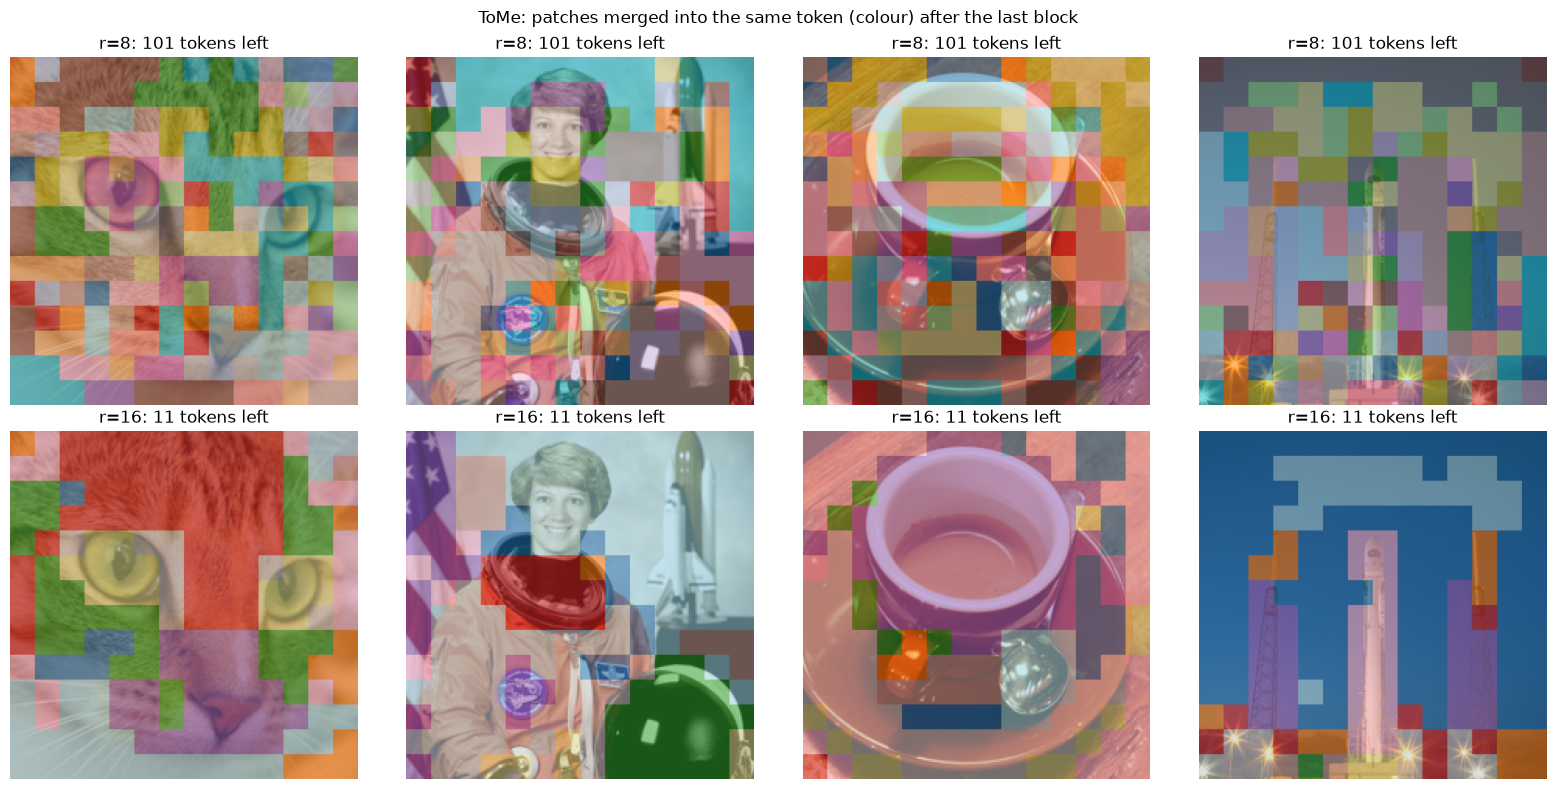

In [28]:
TOME_BASE = "vit_small_patch16_224.augreg_in1k"
timm_vit_s = timm.create_model(TOME_BASE, pretrained=True).eval()
tome_vit = VisionTransformer(embed_dim=384, depth=12, num_heads=6).eval()
print(tome_vit.load_state_dict(timm_vit_s.state_dict(), strict=True))
apply_tome(tome_vit, r=0).to(DEVICE)

# Visualize which patches end up merged together.
# The sequence shrinks by r per block, but never by more than (N - 1) / 2 per step: r = 16 leaves 11 tokens.
x_nat, mean, std = preprocess_for(timm_vit_s, natural_images.values())
fig, axes = plt.subplots(2, len(natural_images), figsize=(4 * len(natural_images), 8))
for row, r in enumerate([8, 16]):
    apply_tome(tome_vit, r)
    with torch.no_grad():
        _, source = tome_forward(tome_vit, x_nat.to(DEVICE), track_source=True)
    groups = source[:, 1:, 1:].argmax(dim=1).cpu()          # final token id for every patch (ignore [CLS])
    for i in range(len(natural_images)):
        img = denormalize(x_nat[i], mean, std)
        seg = F.interpolate(groups[i].reshape(1, 1, 14, 14).float(), size=224, mode="nearest")[0, 0]
        axes[row, i].imshow(img)
        axes[row, i].imshow(seg, cmap="tab20", alpha=0.55)
        axes[row, i].set_title(f"r={r}: {source.shape[1]} tokens left")
        axes[row, i].axis("off")
plt.suptitle("ToMe: patches merged into the same token (colour) after the last block")
plt.tight_layout()
plt.show()

In [29]:
def tokens_after_merging(n_tokens, r, depth):
    for _ in range(depth):
        n_tokens -= min(r, (n_tokens - 1) // 2)
    return n_tokens


tome_path = os.path.join(RESULTS_DIR, "tome_results.csv")
if RUN_EXPERIMENTS:
    rows = []
    for r in [0, 4, 8, 13, 16]:     # r = 13 is the ToMe paper's operating point for ViT-S
        apply_tome(tome_vit, r)
        fwd = lambda x: tome_forward(tome_vit, x)
        acc = evaluate_on_imagenet_subset(tome_vit, woof_loader_vit, DEVICE, forward_fn=fwd)
        rows.append({
            "r (tokens merged per block)": r,
            "tokens after last block": tokens_after_merging(197, r, depth=12),
            "Imagewoof top-1 (10-way)": acc["top1_subset"],
            "Imagewoof top-1 (1000-way)": acc["top1_imagenet"],
            "throughput, img/s": measure_throughput(fwd, DEVICE),
        })
    tome_df = pd.DataFrame(rows)
    tome_df["speed-up"] = tome_df["throughput, img/s"] / tome_df["throughput, img/s"].iloc[0]
    tome_df.to_csv(tome_path, index=False)
else:
    tome_df = pd.read_csv(tome_path)
tome_df.round(4)

,r (tokens merged per block),tokens after last block,Imagewoof top-1 (10-way),Imagewoof top-1 (1000-way),"throughput, img/s",speed-up
0,0,197,0.9766,0.8651,4142.9699,1.0000
1,4,149,0.9735,0.8600,4304.8376,1.0391
2,8,101,0.9712,0.8509,4876.2523,1.1770
3,13,41,0.9633,0.8211,5856.2398,1.4135
4,16,11,0.9544,0.7875,6222.4964,1.5019


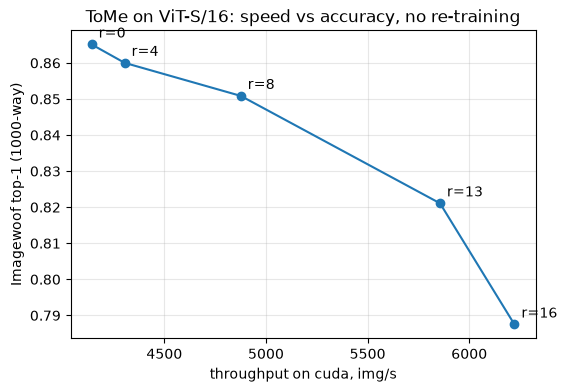

In [30]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(tome_df["throughput, img/s"], tome_df["Imagewoof top-1 (1000-way)"], marker="o")
for _, row in tome_df.iterrows():
    ax.annotate(f"r={int(row['r (tokens merged per block)'])}",
                (row["throughput, img/s"], row["Imagewoof top-1 (1000-way)"]), textcoords="offset points", xytext=(5, 5))
ax.set_xlabel(f"throughput on {DEVICE}, img/s"); ax.set_ylabel("Imagewoof top-1 (1000-way)")
ax.set_title("ToMe on ViT-S/16: speed vs accuracy, no re-training")
ax.grid(alpha=0.3)
plt.show()

Two lessons from this sweep:

* **Accuracy degrades gracefully** for moderate $r$ and faster for aggressive merging — and the drop is much more visible on the harder 1000-way metric than on the saturated 10-way one.
* **The speed-up depends on the hardware and the model size.** Merging costs gathers, scatters and a sort in every block. For a small ViT-S on a fast GPU the attention/MLP matmuls are cheap, so the overhead eats a large part of the gain: we see at most ~1.5x here, while the ToMe paper reports ~2x for ViT-L/H, where the matmuls dominate. Small-model timings are also **noisy**: on another RTX 5090 host the same sweep made $r = 16$ *slower* than $r = 13$. Measure on your model and your device, with enough repetitions.

<a id='Hybrid'></a>
# Hybrid convolutional-transformer architectures

Convolutions and attention are complementary:

| | Convolution | Self-attention |
|---|---|---|
| Receptive field | local | global |
| Weights | static, shared over positions | dynamic, input-dependent |
| Inductive bias | strong (locality, translation equivariance) | weak |
| Cost vs resolution | linear | quadratic |
| Generalizes from little data | ✅ | ❌ |
| Scales with data / capacity | saturates earlier | ✅ |

**CoAtNet** (Dai et al., 2021) studied how to stack them and found a simple rule: **convolutions in early, high-resolution stages; attention in late, low-resolution stages** (C-C-T-T). Early layers need local patterns and must be cheap at high resolution; late layers benefit from global reasoning over a small number of tokens.

## A zoo of hybrids

| Model | Where do convolutions go? | Main target |
|---|---|---|
| **ViT-hybrid** (ViT paper) | ResNet stem produces the tokens | accuracy |
| **Early convs** (Xiao et al.) | replace the $16 \times 16$ patchify with a few stride-2 $3 \times 3$ convs | optimization stability, +1-2% |
| **CvT** | convolutional token embedding + convolutional $\mathbf{Q}, \mathbf{K}, \mathbf{V}$ projections | accuracy, no positional embedding |
| **CoAtNet** | MBConv stages then relative-attention stages | accuracy at scale |
| **LeViT** | conv stem, attention with BN, shrinking attention | CPU/GPU latency |
| **MobileViT** | MobileNetV2 blocks + transformers operating on unfolded patches | mobile |
| **EfficientFormer / FastViT** | CNN-like (pooling / reparameterized depthwise conv) early stages, attention only at the end | mobile latency |
| **MaxViT** | MBConv + block (window) attention + grid attention in every block | accuracy, dense tasks |

## Early convolutions: a conv stem instead of patchify

A $16 \times 16$ stride-16 patchify is an aggressive, "non-overlapping" downsampling with a large kernel — hard to optimize. Xiao et al. replace it with a stack of $3 \times 3$ stride-2 convolutions (+BN+ReLU) followed by a $1 \times 1$ projection, adding only ~1 transformer block worth of FLOPs. The resulting ViTs converge faster, are much less sensitive to the optimizer/learning rate, and are more accurate.

In [31]:
class ConvStem(nn.Module):
    """Early-convolution stem (Xiao et al., 2021): 4 x (3x3 conv, stride 2) + 1x1 projection -> stride 16."""

    def __init__(self, in_chans=3, embed_dim=384, channels=(48, 96, 192, 384)):
        super().__init__()
        layers, prev = [], in_chans
        for ch in channels:
            layers += [nn.Conv2d(prev, ch, 3, stride=2, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True)]
            prev = ch
        layers.append(nn.Conv2d(prev, embed_dim, 1))
        self.proj = nn.Sequential(*layers)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)     # (B, N, D), same interface as PatchEmbed


patchify = nn.Conv2d(3, 384, 16, 16)
stem = ConvStem(embed_dim=384)
x = torch.randn(1, 3, 224, 224)
print("patchify:", tuple(patchify(x).flatten(2).transpose(1, 2).shape), f"{count_gmacs(patchify):.3f} GMACs")
print("conv stem:", tuple(stem(x).shape), f"{count_gmacs(stem):.3f} GMACs  (one ViT-S block ~ 0.35 GMACs)")

patchify: (1, 196, 384) 0.058 GMACs
conv stem: (1, 196, 384) 0.435 GMACs  (one ViT-S block ~ 0.35 GMACs)


## MaxViT: window + grid attention

<img src="https://raw.githubusercontent.com/google-research/maxvit/main/doc/maxvit_arch.png" width="700">

You met MaxViT in the previous course. The one idea worth implementing: every block has **block attention** (local $P \times P$ windows) followed by **grid attention** (a *dilated* $G \times G$ grid spread over the whole image). With a fixed partition size the cost is linear in the image size, yet every block has a global receptive field — no shifting needed. The two partitions differ only in the order of axes in the reshape:

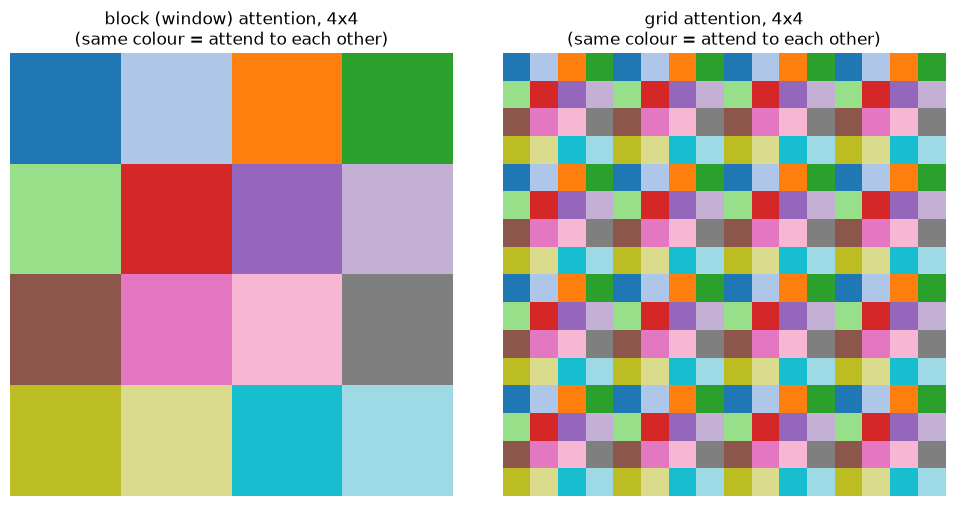

In [32]:
def block_partition(x, p):
    """(B, H, W, C) -> (B * num_windows, p*p, C): contiguous p x p windows."""
    return rearrange(x, "b (nh ph) (nw pw) c -> (b nh nw) (ph pw) c", ph=p, pw=p)


def grid_partition(x, g):
    """(B, H, W, C) -> (B * num_groups, g*g, C): a g x g grid of tokens with stride H/g (dilated)."""
    return rearrange(x, "b (gh nh) (gw nw) c -> (b nh nw) (gh gw) c", gh=g, gw=g)


Hg = 16
ids = torch.arange(Hg * Hg).reshape(1, Hg, Hg, 1).float()
group_of = {}
for name, fn in [("block (window) attention, 4x4", block_partition), ("grid attention, 4x4", grid_partition)]:
    groups = fn(ids, 4)[..., 0]                   # (num_groups, 16) token ids
    label = torch.zeros(Hg * Hg)
    for gidx, members in enumerate(groups.long()):
        label[members] = gidx
    group_of[name] = label.reshape(Hg, Hg)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (name, label) in zip(axes, group_of.items()):
    ax.imshow(label, cmap="tab20")
    ax.set_title(f"{name}\n(same colour = attend to each other)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## ConvNeXt: the CNN strikes back

(Recap from the previous course.) ConvNeXt "modernized" a ResNet step by step with Swin's design choices — ViT training recipe, patchify stem, large depthwise kernels, inverted bottleneck, LayerNorm, GELU — and matched Swin at every scale. **Lesson:** a large part of the "transformer advantage" in 2020-2021 came from the **training recipe** and **macro design**, not from attention itself. Today the choice between them is driven by pre-training availability, hardware and downstream tasks.

<a id='Dense'></a>
# Plain ViTs for dense prediction

The hierarchical designs were motivated by detection and segmentation. **ViTDet** (Li et al., 2022) showed that with strong (MAE) pre-training this is not necessary:

1. Keep the **plain** ViT backbone (single $1/16$ scale); use **window attention** in most blocks and just **4 global attention blocks** to afford high resolution ($1024 \times 1024$).
2. Build a **simple feature pyramid** from the last feature map only: deconvolutions for strides 4 and 8, identity for 16, max-pooling for 32. No FPN top-down path is needed.

The **SAM** image encoder uses the same windowed plain-ViT backbone (with a simple single-scale stride-16 neck instead of the pyramid). Alternatives: **ViT-Adapter** injects a convolutional spatial-prior branch into a plain ViT; **DPT** reassembles tokens from several layers.

In [33]:
class LayerNorm2d(nn.LayerNorm):
    def forward(self, x):
        return super().forward(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)


class SimpleFeaturePyramid(nn.Module):
    """ViTDet: multi-scale features (strides 4, 8, 16, 32) from a single stride-16 ViT feature map."""

    def __init__(self, dim, out_dim=256):
        super().__init__()
        self.scales = nn.ModuleList([
            nn.Sequential(nn.ConvTranspose2d(dim, dim // 2, 2, stride=2), LayerNorm2d(dim // 2), nn.GELU(),
                          nn.ConvTranspose2d(dim // 2, dim // 4, 2, stride=2)),      # stride 4
            nn.ConvTranspose2d(dim, dim // 2, 2, stride=2),                          # stride 8
            nn.Identity(),                                                           # stride 16
            nn.MaxPool2d(2),                                                         # stride 32
        ])
        in_dims = [dim // 4, dim // 2, dim, dim]
        self.out = nn.ModuleList([
            nn.Sequential(nn.Conv2d(c, out_dim, 1), LayerNorm2d(out_dim), nn.Conv2d(out_dim, out_dim, 3, padding=1))
            for c in in_dims
        ])

    def forward(self, x):                   # x: (B, D, H/16, W/16)
        return [out(scale(x)) for scale, out in zip(self.scales, self.out)]


vit_s_dyn = timm.create_model("vit_small_patch16_224", dynamic_img_size=True)
vit_feat = vit_s_dyn.forward_intermediates(torch.randn(1, 3, 512, 512), indices=[11], intermediates_only=True)[-1]
pyramid = SimpleFeaturePyramid(384)(vit_feat)
print("ViT-S/16 last feature map @512px:", tuple(vit_feat.shape))
for f in pyramid:
    print(f"  stride {512 // f.shape[-1]:>2}: {tuple(f.shape)}")

ViT-S/16 last feature map @512px: (1, 384, 32, 32)
  stride  4: (1, 256, 128, 128)
  stride  8: (1, 256, 64, 64)
  stride 16: (1, 256, 32, 32)
  stride 32: (1, 256, 16, 16)


<a id='SOTA_2026'></a>
# Where the field is in 2025–2026

Which of the ideas from this lecture survived in the vision encoders that are actually used today?

| Model (date) | Backbone | Positions | Resolution / aspect ratio | Notable |
|---|---|---|---|---|
| **DINOv3** (Meta, Aug 2025) | plain ViT-7B/16 (40 blocks, $D = 4096$, SwiGLU), distilled into ViT-S/B/L/H+ and **ConvNeXt** | **RoPE** with coordinates in a $[-1, 1]$ box + random box jittering (scale $0.5$–$2$) | high-resolution adaptation stage (512–768 px) | **4 registers**; **Gram anchoring** keeps dense features local during very long training |
| **SigLIP 2** (Google, Feb 2025) | plain ViT (B … g), $P = 16$ | learned absolute | **NaFlex** variant: native aspect ratio, variable sequence length | multilingual contrastive image-text encoder with strong dense features |
| **Perception Encoder** (Meta, 2025) | plain ViT (L+ 450M … G) | 2D-RoPE + absolute | — | CLIP-style contrastive training; backbone of SAM 3 |
| **SAM 3** (Meta, Nov 2025) | **plain ViT** (PE L+), **back from Hiera** used in SAM 2 | RoPE in every layer + windowed absolute | 1008 px | ViTDet-style: windowed attention ($24 \times 24$ tokens) and **global attention in only 4 of 32 layers** |
| **C-RADIOv4** (NVIDIA, Jan–Feb 2026) | plain ViT (SO400M, H) distilled from SigLIP2-g + DINOv3-7B + SAM 3 ("agglomerative") | — | any resolution 128–1152 px (up to 2048) in steps of 16 | optional ViTDet mode with **4 global layers**; shift-equivariant losses remove border / window artifacts of the teachers |

### What converged

* **Plain ViT won the foundation-model race.** Hierarchical transformers remain good task-specific backbones, but the big pre-trained encoders are plain ViTs — SAM 3 even moved *back* from Hiera to a plain ViT. Multi-scale features for dense tasks are obtained ViTDet-style (windowed attention + a handful of global blocks + a simple pyramid), exactly as in the section above.
* **RoPE (2D / axial) is the default** positional encoding, usually together with (interpolated) absolute embeddings; a learned absolute table alone is disappearing.
* **"Hygiene" is standard:** registers (DINOv2/v3), LayerScale, QK-norm; DINOv3 adds Gram anchoring against the degradation of dense features.
* **Distillation everywhere:** huge teachers (DINOv3-7B, SigLIP2-g) are distilled into small ViTs and even ConvNeXts; agglomerative models (C-RADIO) merge several teachers into one backbone.

<a id='Benchmark'></a>
# Benchmark: 16 architectures on the same data

All checkpoints below were trained on **ImageNet-1k only** (some with distillation), at $224 \times 224$ — so the comparison is roughly fair. For each model we measure:

* **params** and **GMACs** for one $224 \times 224$ image;
* **throughput** (images/s, batch 64, inference) on *our* device — this depends heavily on hardware and kernels: FLOPs $\neq$ latency;
* **Imagewoof top-1** with the model's own preprocessing, in two variants: **10-way** (argmax over the 10 Imagewoof classes only) and **1000-way** (argmax over all ImageNet classes — among 120 dog breeds, a much harder and more informative test).

> ⏱️ Takes a few minutes: every checkpoint is downloaded from the HuggingFace Hub on the first run.

In [34]:
BENCHMARK_MODELS = {
    # name: (family, timm checkpoint)
    "ResNet-50 (A1)": ("CNN", "resnet50.a1_in1k"),
    "ConvNeXt-T": ("CNN (modernized)", "convnext_tiny.fb_in1k"),
    "ViT-S/16 (AugReg)": ("plain ViT", "vit_small_patch16_224.augreg_in1k"),
    "DeiT-S": ("plain ViT", "deit_small_patch16_224.fb_in1k"),
    "DeiT-S distilled": ("plain ViT", "deit_small_distilled_patch16_224.fb_in1k"),
    "DeiT III-S": ("plain ViT", "deit3_small_patch16_224.fb_in1k"),
    "RoPE-ViT-S": ("plain ViT", "vit_small_patch16_rope_224.naver_in1k"),
    "Swin-T": ("hierarchical", "swin_tiny_patch4_window7_224.ms_in1k"),
    "PVTv2-B2": ("hierarchical", "pvt_v2_b2.in1k"),
    "Hiera-T (MAE)": ("hierarchical", "hiera_tiny_224.mae_in1k_ft_in1k"),
    "MaxViT-T": ("hybrid", "maxvit_tiny_tf_224.in1k"),
    "CoAtNet-0": ("hybrid", "coatnet_0_rw_224.sw_in1k"),
    "LeViT-256": ("hybrid (efficient)", "levit_256.fb_dist_in1k"),
    "EfficientFormer-L1": ("hybrid (efficient)", "efficientformer_l1.snap_dist_in1k"),
    "FastViT-T12": ("hybrid (efficient)", "fastvit_t12.apple_in1k"),
    "MobileViT-S": ("hybrid (mobile)", "mobilevit_s.cvnets_in1k"),
}

In [35]:
bench_path = os.path.join(RESULTS_DIR, "benchmark_results.csv")
rows = []
for name, (family, ckpt) in BENCHMARK_MODELS.items() if RUN_EXPERIMENTS else []:
    model = timm.create_model(ckpt, pretrained=True).eval()
    if "fastvit" in ckpt:
        model = reparameterize_model(model)        # fuse train-time branches into single convs for inference

    # GMACs: count on CPU with non-fused attention (so that attention matmuls are visible to the counter)
    timm.layers.set_fused_attn(False)
    flop_model = timm.create_model(ckpt, pretrained=False).eval()
    timm.layers.set_fused_attn(True)
    if "fastvit" in ckpt:
        flop_model = reparameterize_model(flop_model)
    try:
        gmacs = count_gmacs(flop_model, 224)
    except RuntimeError:
        # some models (e.g. Hiera in timm 1.0.x) only support the fused path -> attention matmuls are not counted,
        # the GMACs of such models are slightly underestimated
        gmacs = count_gmacs(timm.create_model(ckpt, pretrained=False).eval(), 224)

    model = model.to(DEVICE)
    loader = make_eval_loader(IMAGEWOOF_VAL, model, batch_size=64, num_workers=NUM_WORKERS)
    acc = evaluate_on_imagenet_subset(model, loader, DEVICE)
    rows.append({
        "model": name,
        "family": family,
        "params, M": sum(p.numel() for p in model.parameters()) / 1e6,
        "GMACs": gmacs,
        "throughput, img/s": measure_throughput(model, DEVICE, img_size=224, batch_size=64),
        "top-1 (10-way)": acc["top1_subset"],
        "top-1 (1000-way)": acc["top1_imagenet"],
    })
    print(f"{name:<20} done: 10-way {acc['top1_subset']:.4f} | 1000-way {acc['top1_imagenet']:.4f}")
    del model

if RUN_EXPERIMENTS:
    pd.DataFrame(rows).to_csv(bench_path, index=False)
bench_df = pd.read_csv(bench_path).round(3)
bench_df.sort_values("top-1 (1000-way)", ascending=False)

ResNet-50 (A1)       done: 10-way 0.9781 | 1000-way 0.8908


ConvNeXt-T           done: 10-way 0.9801 | 1000-way 0.9071


ViT-S/16 (AugReg)    done: 10-way 0.9766 | 1000-way 0.8651


DeiT-S               done: 10-way 0.9707 | 1000-way 0.8643


DeiT-S distilled     done: 10-way 0.9712 | 1000-way 0.8608


...

LeViT-256            done: 10-way 0.9801 | 1000-way 0.9053


EfficientFormer-L1   done: 10-way 0.9740 | 1000-way 0.8707


FastViT-T12          done: 10-way 0.9751 | 1000-way 0.8633


MobileViT-S          done: 10-way 0.9745 | 1000-way 0.8743


,model,family,"params, M",GMACs,"throughput, img/s",top-1 (10-way),top-1 (1000-way)
11,CoAtNet-0,hybrid,27.436,4.406,2809.979,0.984,0.913
9,Hiera-T (MAE),hierarchical,27.910,4.901,2870.338,0.982,0.913
1,ConvNeXt-T,CNN (modernized),28.589,4.456,1673.222,0.980,0.907
12,LeViT-256,hybrid (efficient),18.894,1.127,6370.482,0.980,0.905
0,ResNet-50 (A1),CNN,25.557,4.089,3890.725,0.978,0.891
10,MaxViT-T,hybrid,30.917,5.552,1451.778,0.974,0.881
7,Swin-T,hierarchical,28.288,4.491,2655.119,0.977,0.877
8,PVTv2-B2,hierarchical,25.363,4.027,2003.674,0.978,0.876
15,MobileViT-S,hybrid (mobile),5.579,1.522,3321.623,0.975,0.874
6,RoPE-ViT-S,plain ViT,21.984,4.599,1548.560,0.972,0.871


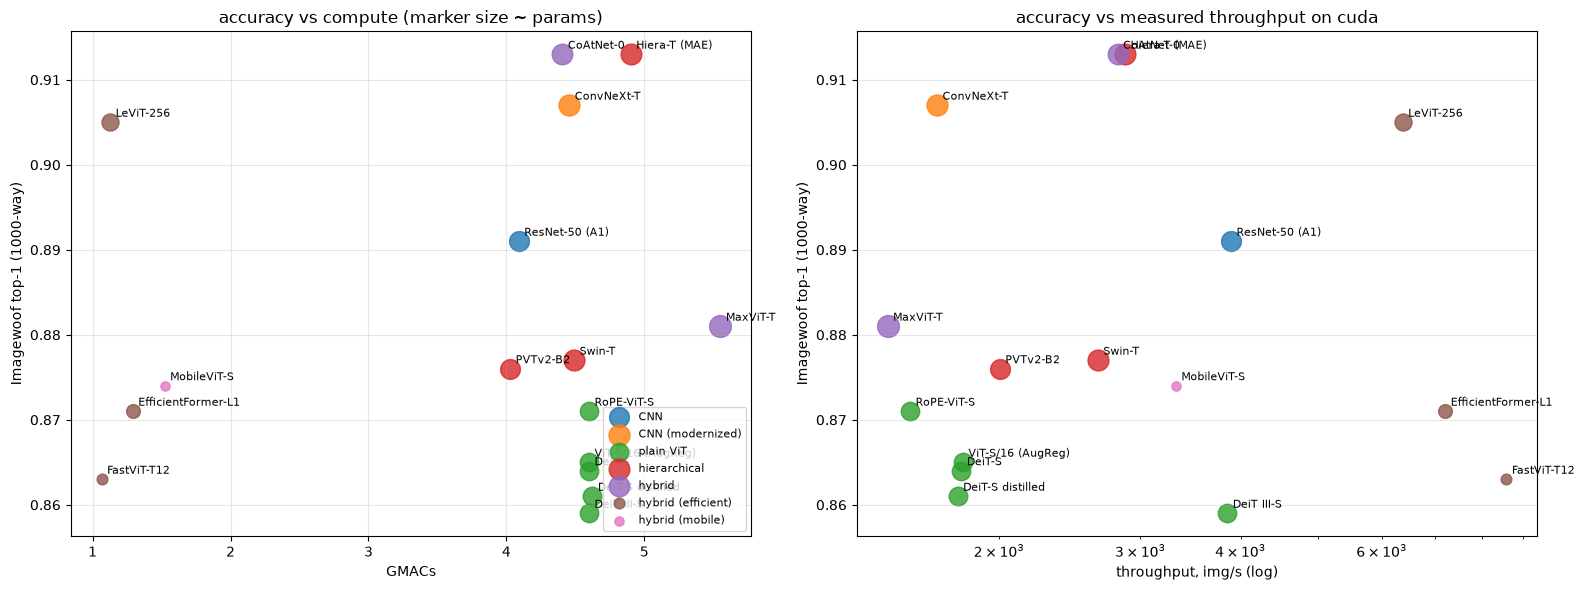

In [36]:
families = bench_df["family"].unique()
colors = dict(zip(families, plt.cm.tab10(np.arange(len(families)))))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, xcol, logx in [(axes[0], "GMACs", False), (axes[1], "throughput, img/s", True)]:
    for _, row in bench_df.iterrows():
        ax.scatter(row[xcol], row["top-1 (1000-way)"], s=row["params, M"] * 8, color=colors[row["family"]], alpha=0.8,
                   label=row["family"])
        ax.annotate(row["model"], (row[xcol], row["top-1 (1000-way)"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel(xcol + (" (log)" if logx else "")); ax.set_ylabel("Imagewoof top-1 (1000-way)")
    if logx:
        ax.set_xscale("log")
    ax.grid(alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
uniq = dict(zip(labels, handles))
axes[0].legend(uniq.values(), uniq.keys(), fontsize=8, loc="lower right")
axes[0].set_title("accuracy vs compute (marker size ~ params)")
axes[1].set_title(f"accuracy vs measured throughput on {DEVICE}")
plt.tight_layout()
plt.show()

### How does compute scale with resolution?

The key practical difference between global-attention ViTs and hierarchical / local models shows up at **high resolution** (detection, segmentation, medical images). We count GMACs (with attention matmuls included) for resolutions from 224 to 1120.

,ViT-S/16 (global attention),Swin-T (window attention),PVTv2-B2 (spatial-reduction attn),MaxViT-T (block + grid attention),ConvNeXt-T (CNN)
resolution,,,,,
224,4.6,4.5,4.0,5.6,4.5
448,22.6,18.0,17.8,24.5,17.8
672,66.7,40.4,46.5,64.1,40.1
896,158.2,71.8,98.6,137.2,71.3
1120,326.9,112.2,186.2,263.2,111.4


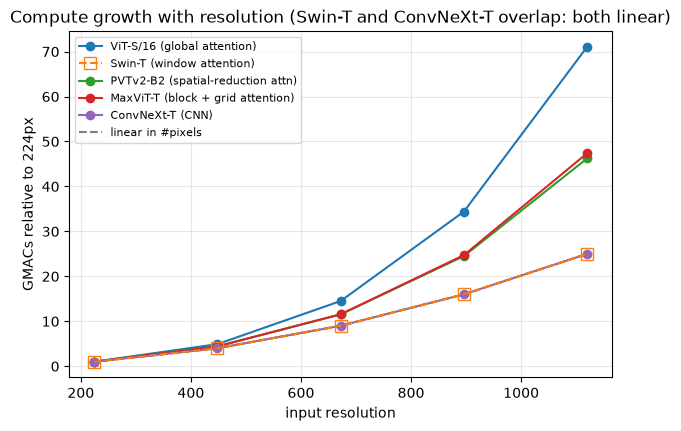

In [37]:
timm.layers.set_fused_attn(False)
scaling_models = {
    "ViT-S/16 (global attention)": lambda res: timm.create_model("vit_small_patch16_224", img_size=res),
    "Swin-T (window attention)": lambda res: timm.create_model("swin_tiny_patch4_window7_224", img_size=res),
    "PVTv2-B2 (spatial-reduction attn)": lambda res: timm.create_model("pvt_v2_b2"),
    "MaxViT-T (block + grid attention)": lambda res: timm.create_model("maxvit_tiny_tf_224", img_size=res),
    "ConvNeXt-T (CNN)": lambda res: timm.create_model("convnext_tiny"),
}
resolutions = [224, 448, 672, 896, 1120]
scaling_path = os.path.join(RESULTS_DIR, "gmacs_vs_resolution.csv")
if RUN_EXPERIMENTS:
    scaling = {name: [count_gmacs(fn(res).eval(), res) for res in resolutions] for name, fn in scaling_models.items()}
    pd.DataFrame(scaling, index=pd.Index(resolutions, name="resolution")).to_csv(scaling_path)
timm.layers.set_fused_attn(True)
scaling_df = pd.read_csv(scaling_path, index_col="resolution")
scaling = {name: scaling_df[name].tolist() for name in scaling_df.columns}
display(scaling_df.round(1))

plt.figure(figsize=(7, 4.5))
for name, values in scaling.items():
    is_swin = "Swin" in name
    plt.plot(resolutions, np.array(values) / values[0], label=name, ls="--" if is_swin else "-",
             marker="s" if is_swin else "o", markersize=9 if is_swin else 6, zorder=3 if is_swin else 2,
             markerfacecolor="none" if is_swin else None)
plt.plot(resolutions, [(r / 224) ** 2 for r in resolutions], "k--", alpha=0.5, label="linear in #pixels")
plt.xlabel("input resolution"); plt.ylabel("GMACs relative to 224px")
plt.title("Compute growth with resolution (Swin-T and ConvNeXt-T overlap: both linear)")
plt.grid(alpha=0.3); plt.legend(fontsize=8)
plt.show()

### Takeaways from the benchmark

* **Pick a metric that can discriminate.** The 10-way accuracy is saturated (97-98% for every model), so it cannot rank architectures. The 1000-way accuracy spreads them over ~86-91%.
* **Mind the noise.** With 3,929 images the 95% confidence interval of an accuracy around 88% is about $\pm 1$ point ($1.96\sqrt{p(1-p)/n}$). Differences inside the plain-ViT group (AugReg, DeiT, DeiT distilled, DeiT III, RoPE-ViT: 86-87%) are **not significant** here — even though on the full ImageNet validation set DeiT III and distillation are 1-2 points better. A narrow, fine-grained subset is not ImageNet: always evaluate on data that looks like *your* task.
* **Inductive bias still pays off at ImageNet-1k scale.** The top of the table is taken by models with convolutional stages (CoAtNet, ConvNeXt, LeViT, ResNet-50 with the modern A1 recipe) and by Hiera, whose spatial biases come from MAE pre-training. The window/pyramid transformers (Swin, PVT, MaxViT) are in the middle, and all plain ViT-S variants trained on ImageNet-1k only are in the bottom group (86-87%), together with the smallest efficient hybrids. With web-scale or self-supervised pre-training the picture changes.
* **FLOPs are not latency.** LeViT, EfficientFormer and FastViT (~1.1-1.3 GMACs) run at 6-9k img/s, far faster than the ~4.5-GMAC models; MaxViT is among the slowest despite similar GMACs (many reshapes and small attention windows), and MobileViT is cheap in GMACs but not fast on a GPU (it is optimized for mobile CPUs). Always measure on *your* target device.
* **Timings are noisy.** ViT-S (AugReg), DeiT-S and DeiT III-S are the *same* architecture, yet their measured throughput can differ by up to ~2x in this table (GPU clocks, other tenants on a shared cloud host, too few iterations). Treat single measurements with suspicion: warm up, repeat, report medians.
* At high resolution the **quadratic** attention of the plain ViT dominates the cost. Only models with a *fixed-size* local operator — Swin (7x7 windows) and ConvNeXt (7x7 depthwise convs) — scale linearly with the number of pixels. PVT's spatial-reduction attention is still quadratic (just with an $R^2$ smaller constant), and `timm`'s MaxViT grows its window/grid partition with the input size (7 $\rightarrow$ 35 at 1120px, as in the paper's high-resolution fine-tuning), so both grow super-linearly — though much slower than the plain ViT.

<a id='Choose'></a>
# How to choose a backbone

There is no universally best architecture. A practical decision checklist:

| Situation | Reasonable first choice | Why |
|---|---|---|
| Image classification / retrieval with a strong pre-trained model available | **plain ViT** with the best pre-training you can get (DINOv3, SigLIP 2, Perception Encoder, C-RADIOv4) | plain ViTs have the best pre-trained checkpoints; pre-training matters more than architecture |
| Small dataset, training from scratch | **CNN** (ResNet, ConvNeXt) or a hybrid | inductive bias |
| Detection / segmentation, high resolution | plain ViT + ViTDet-style windows / pyramid (SAM 3, C-RADIOv4 in ViTDet mode) or **hierarchical** (Swin, ConvNeXt, Hiera) | multi-scale features, linear cost |
| Edge / mobile / real-time | **efficient hybrid** (FastViT, EfficientFormer, MobileViT, LeViT) or MobileNet | latency on the device |
| Very long token sequences (gigapixel pathology, video, 3D) | local/linear attention, token merging, or tiling + multi-instance learning | $\mathcal{O}(N^2)$ |

**Always:** (1) check the pre-training data and preprocessing of the checkpoint, (2) measure accuracy **and** latency on your data and your hardware, (3) start from a strong baseline before trying exotic architectures.

The `timm` benchmark code above is a good starting point for comparing ViT-based and convolutional backbones on your own task.

<a id='Summary'></a>
# Summary

* The post-ViT zoo addresses three weaknesses of the vanilla ViT: **data hunger** (DeiT recipe, distillation, LayerScale, self-supervision), **quadratic single-scale attention** (hierarchies, windows, spatial reduction, linear attention, token merging, fused kernels), and **hygiene** (relative / conditional / rotary positions, registers).
* **Swin** = patch merging pyramid + window attention + shifted windows with a cyclic roll and attention mask + relative position bias.
* **PVT** keeps global attention but downsamples keys/values; **MaxViT** combines local window and dilated grid attention.
* **Hybrids** put convolutions where they help most — early, high-resolution stages — and attention where it pays off — late, low-resolution stages.
* **ConvNeXt** shows that much of the early transformer advantage came from the training recipe and macro design.
* **Plain ViTs** remain the default for large-scale pre-training (DINOv3, SigLIP 2, Perception Encoder, SAM 3) and are adapted to dense tasks with windowed attention, a few global blocks and simple feature pyramids.

# Self-check questions

**Theory**
1. What two changes allowed DeiT to train ViT-B on ImageNet-1k only? How does the distillation token differ from [CLS]? Why does a CNN teacher work better than a transformer teacher?
2. Why does Swin need *shifted* windows? Explain the cyclic shift and why an attention mask is required.
3. Compare the ways PVT, Swin and MaxViT make attention affordable at high resolution. Which of them keep a global receptive field in every block? Which of them are truly linear in the number of pixels?
4. Why does linear attention scale as $\mathcal{O}(N)$? What do we lose compared to softmax attention?
5. How does ToMe reduce the number of tokens without retraining? What goes wrong in the softmax without proportional attention ($+\log \mathbf{s}$)?
6. What are the high-norm artifact tokens described in "Vision Transformers Need Registers", and how do registers remove them? What problem does QK-norm solve?
7. Show that 2D RoPE makes the attention score depend only on the relative position of the query and key. Why does it transfer to new resolutions better than a learned absolute table?
8. According to CoAtNet, where should convolutions and attention be placed and why?

**Practice**
1. Swin-T stage 1: $56 \times 56$ tokens, $C = 96$, $M = 7$. Compute the MACs of MSA and W-MSA. At what input resolution does global attention in stage 1 cost 10x more than window attention?
2. You add 4 register tokens to our Lecture 1 `VisionTransformer`. Which tensors change shape? Which pretrained weights can still be loaded and how do you initialize the rest?
3. A checkpoint contains the keys `layers.0.blocks.1.attn.relative_position_bias_table` of shape `(169, 3)` and `layers.1.downsample.reduction.weight` of shape `(192, 384)`. Which architecture is it? What are the window size, the number of heads and the channel width in stage 1?
4. Derive the PI-resize formula $\mathbf{w}' = (\mathbf{B}^\top)^{+}\mathbf{w}$ from the requirement $\langle \mathbf{B}\mathbf{x}, \mathbf{w}' \rangle = \langle \mathbf{x}, \mathbf{w} \rangle$. Why does naive kernel resizing fail?
5. You need a backbone for a $1024 \times 1024$ medical segmentation task with ~2,000 labelled images and one 24 GB GPU. Which architectures and pre-trainings would you shortlist and why?

<a id='Appendix'></a>
# Appendix

## A. Linear attention

Softmax attention computes $(\mathbf{Q}\mathbf{K}^\top)\mathbf{V}$ — the $N \times N$ product comes first. If we replace the softmax similarity with a kernel $\mathrm{sim}(\mathbf{q}, \mathbf{k}) = \phi(\mathbf{q})^\top \phi(\mathbf{k})$ with a positive feature map (e.g. $\phi(x) = \mathrm{elu}(x) + 1$), matrix associativity lets us compute $\phi(\mathbf{Q})\big(\phi(\mathbf{K})^\top \mathbf{V}\big)$ instead:

$$
\mathbf{o}_i = \frac{\phi(\mathbf{q}_i)^\top \sum_j \phi(\mathbf{k}_j)\mathbf{v}_j^\top}{\phi(\mathbf{q}_i)^\top \sum_j \phi(\mathbf{k}_j)} \qquad \Rightarrow \qquad \mathcal{O}(N d^2) \text{ instead of } \mathcal{O}(N^2 d).
$$

The catch: the kernel is a much weaker similarity than softmax (it cannot produce sharp, peaked attention), so accuracy usually drops — linear attention is mostly used in the high-resolution stages of efficient hybrids (e.g. EfficientViT).

In [38]:
def linear_attention(q, k, v, eps=1e-6):
    """q, k, v: (B, h, N, d). O(N d^2) attention with phi(x) = elu(x) + 1."""
    q, k = F.elu(q) + 1, F.elu(k) + 1
    kv = k.transpose(-2, -1) @ v                                  # (B, h, d, d)  -- summary of all keys/values
    normalizer = q @ k.sum(dim=-2, keepdim=True).transpose(-2, -1)   # (B, h, N, 1)
    return (q @ kv) / (normalizer + eps)


rows = []
h, d = 6, 64
for n in [1024, 4096, 8192, 16384] if DEVICE == "cuda" else [1024, 2048, 4096]:
    q, k, v = torch.randn(3, 1, h, n, d, device=DEVICE).unbind(0)
    rows.append({
        "N": n,
        "softmax SDPA (fused), ms": benchmark_fn(lambda: F.scaled_dot_product_attention(q, k, v), DEVICE, n_iters=5),
        "linear attention, ms": benchmark_fn(lambda: linear_attention(q, k, v), DEVICE, n_iters=5),
    })
lin_bench = pd.DataFrame(rows)
lin_bench

,N,"softmax SDPA (fused), ms","linear attention, ms"
0,1024,0.111014,0.171904
1,4096,1.042536,0.172808
2,8192,3.346596,0.276928
3,16384,13.036415,0.556722


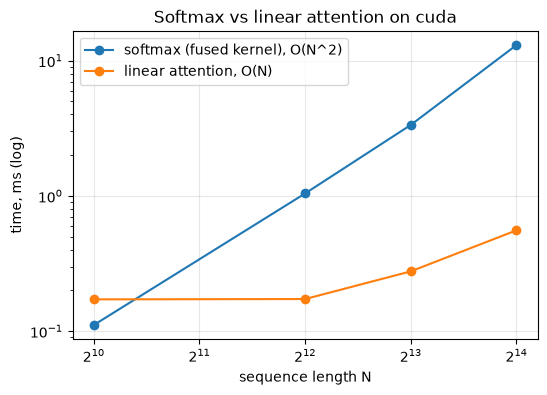

In [39]:
plt.figure(figsize=(6, 4))
plt.plot(lin_bench["N"], lin_bench["softmax SDPA (fused), ms"], marker="o", label="softmax (fused kernel), O(N^2)")
plt.plot(lin_bench["N"], lin_bench["linear attention, ms"], marker="o", label="linear attention, O(N)")
plt.xscale("log", base=2); plt.yscale("log")
plt.xlabel("sequence length N"); plt.ylabel("time, ms (log)")
plt.title(f"Softmax vs linear attention on {DEVICE}")
plt.grid(alpha=0.3); plt.legend()
plt.show()

## B. Do [CLS] and [DIST] tokens learn the same thing?

The DeiT paper reports (for DeiT-B) that the learned [CLS] and [DIST] embeddings are nearly orthogonal at the input (cosine similarity $\approx 0.06$) and become similar, but not identical, at the output ($\approx 0.93$): the distillation token carries complementary information. Let's measure it for the DeiT-S checkpoint on Imagewoof. (In our measurement DeiT-S starts from much more similar tokens than the paper's DeiT-B, but the output similarity matches the paper.)

input, learned tokens only:             0.7318209409713745
input, tokens + positional embeddings:  0.7626737356185913


output (after final norm):              0.9377416968345642


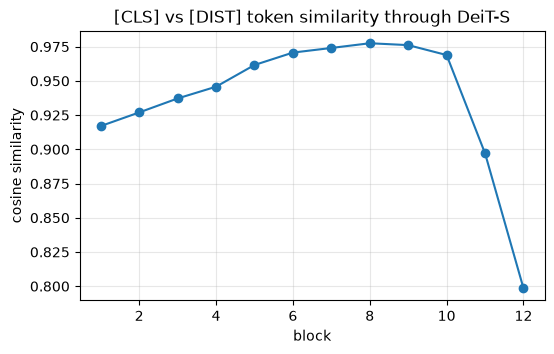

In [40]:
woof_loader = make_eval_loader(IMAGEWOOF_VAL, timm_deit, batch_size=64, num_workers=NUM_WORKERS)
x_woof, _ = next(iter(woof_loader))

with torch.no_grad():
    print("input, learned tokens only:            ",
          F.cosine_similarity(our_deit.cls_token, our_deit.dist_token, dim=-1).item())
    print("input, tokens + positional embeddings: ",
          F.cosine_similarity(our_deit.cls_token + our_deit.pos_embed[:, 0], our_deit.dist_token + our_deit.pos_embed[:, 1], dim=-1).item())
    tokens_per_layer = our_deit.forward_tokens(x_woof)
    sims = [F.cosine_similarity(t[:, 0], t[:, 1], dim=-1).mean().item() for t in tokens_per_layer]
    final = our_deit.norm(tokens_per_layer[-1])
    print("output (after final norm):             ", F.cosine_similarity(final[:, 0], final[:, 1], dim=-1).mean().item())

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(sims) + 1), sims, marker="o")
plt.xlabel("block"); plt.ylabel("cosine similarity")
plt.title("[CLS] vs [DIST] token similarity through DeiT-S")
plt.grid(alpha=0.3)
plt.show()